In [1]:
import matplotlib.pyplot as plt
import os
import pandas as pd
import pickle
import random
import time
import seaborn as sns
import numpy as np
import lightgbm as lgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from matplotlib.ticker import FormatStrFormatter
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error, f1_score, classification_report, roc_auc_score, make_scorer, precision_recall_fscore_support
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import randint

## Объединение датасетов и очистка данных

In [3]:
df_sessions = pd.read_csv('data/ga_sessions.csv')
df_sessions

/var/folders/p0/ykk516gx4yl4sg0c64v939gh0000gn/T/ipykernel_5113/1710953944.py:1: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df_sessions = pd.read_csv('data/ga_sessions.csv')


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,9055434745589932991.1637753792.1637753792,2108382700.163775,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust
1,905544597018549464.1636867290.1636867290,210838531.163687,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.162225,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.162225,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,9055415581448263752.1640159305.1640159305,2108378238.164016,2021-12-22,10:48:25,1,BHcvLfOaCWvWTykYqHVe,cpc,NaN,NaN,VlqBmecIOXWjCWUmQkLd,desktop,Windows,NaN,NaN,1920x1080,Chrome,Russia,Moscow
1860038,9055421130527858185.1622007305.1622007305,2108379530.162201,2021-05-26,08:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Apple,NaN,390x844,Safari,Russia,Stavropol
1860039,9055422955903931195.1636979515.1636979515,2108379955.163698,2021-11-15,15:31:55,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,iOS,Apple,NaN,375x667,Safari,Russia,Moscow
1860040,905543020766873816.1638189404.1638189404,210838164.163819,2021-11-29,15:36:44,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,NaN,393x851,Chrome,Russia,Chelyabinsk


In [4]:
df_hits = pd.read_csv('data/ga_hits.csv')
df_hits

,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,NaN
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,NaN
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,NaN
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,NaN
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
15726465,6866159858916559617.1640270865.1640270865,2021-12-23,810589.0,43,event,NaN,sberauto.com/cars/all/toyota/fortuner/24cb5af2...,quiz,quiz_show,NaN,NaN
15726466,7310304587364460692.1640261783.1640261783,2021-12-23,904927.0,40,event,NaN,sberauto.com/cars/all/mercedes-benz/gla-klasse...,quiz,quiz_show,NaN,NaN
15726467,8013702685784312179.1640270195.1640270195,2021-12-23,2172865.0,43,event,NaN,sberauto.com/cars/all/toyota/alphard/2ebe4871?...,quiz,quiz_show,NaN,NaN
15726468,8021505554734405918.1640257821.1640257821,2021-12-23,713325.0,45,event,NaN,sberauto.com/cars/all/bmw/x3/6a660f0a?rental_p...,quiz,quiz_show,NaN,NaN


In [5]:
df_sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 18 columns):
 #   Column                    Dtype 
---  ------                    ----- 
 0   session_id                object
 1   client_id                 object
 2   visit_date                object
 3   visit_time                object
 4   visit_number              int64 
 5   utm_source                object
 6   utm_medium                object
 7   utm_campaign              object
 8   utm_adcontent             object
 9   utm_keyword               object
 10  device_category           object
 11  device_os                 object
 12  device_brand              object
 13  device_model              object
 14  device_screen_resolution  object
 15  device_browser            object
 16  geo_country               object
 17  geo_city                  object
dtypes: int64(1), object(17)
memory usage: 255.4+ MB


In [6]:
df_hits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15726470 entries, 0 to 15726469
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   session_id      object 
 1   hit_date        object 
 2   hit_time        float64
 3   hit_number      int64  
 4   hit_type        object 
 5   hit_referer     object 
 6   hit_page_path   object 
 7   event_category  object 
 8   event_action    object 
 9   event_label     object 
 10  event_value     float64
dtypes: float64(2), int64(1), object(8)
memory usage: 1.3+ GB


In [7]:
df_hits.nunique(dropna=False)

session_id        1734610
hit_date              226
hit_time           925888
hit_number            500
hit_type                1
hit_referer         37874
hit_page_path      342715
event_category         52
event_action          230
event_label         39826
event_value             1
dtype: int64

In [8]:
df_sessions.nunique(dropna=False)

session_id                  1860042
client_id                   1391717
visit_date                      226
visit_time                    85318
visit_number                    537
utm_source                      294
utm_medium                       56
utm_campaign                    413
utm_adcontent                   287
utm_keyword                    1220
device_category                   3
device_os                        14
device_brand                    206
device_model                    105
device_screen_resolution       5039
device_browser                   57
geo_country                     166
geo_city                       2548
dtype: int64

In [9]:
# Список целевых действий
target_actions = [
    'sub_car_claim_click', 'sub_car_claim_submit_click',
    'sub_open_dialog_click', 'sub_custom_question_submit_click',
    'sub_call_number_click', 'sub_callback_submit_click',
    'sub_submit_success', 'sub_car_request_submit_click'
]

# Создаем столбец is_target
df_hits['target'] = df_hits['event_action'].isin(target_actions).astype(int)

# Подсчет количества целевых и нецелевых
target_counts = df_hits['target'].value_counts()
print("Количество строк с целевыми и нецелевыми event_action:")
print(f"Целевые (target=1): {target_counts.get(1, 0)}")
print(f"Нецелевые (target=0): {target_counts.get(0, 0)}")

# Подсчет пропорций
target_proportions = df_hits['target'].value_counts(normalize=True)
print("\nПропорции целевых и нецелевых event_action:")
print(f"Целевые (target=1): {target_proportions.get(1, 0):.4f}")
print(f"Нецелевые (target=0): {target_proportions.get(0, 0):.4f}")

# Подсчет каждого целевого действия
print("\nКоличество строк для каждого целевого event_action:")
target_action_counts = df_hits[df_hits['event_action'].isin(target_actions)]['event_action'].value_counts()
print(target_action_counts)

Количество строк с целевыми и нецелевыми event_action:
Целевые (target=1): 104908
Нецелевые (target=0): 15621562

Пропорции целевых и нецелевых event_action:
Целевые (target=1): 0.0067
Нецелевые (target=0): 0.9933

Количество строк для каждого целевого event_action:
event_action
sub_car_claim_click                 37928
sub_open_dialog_click               25870
sub_submit_success                  18439
sub_car_claim_submit_click          12359
sub_call_number_click                3653
sub_callback_submit_click            3074
sub_car_request_submit_click         2966
sub_custom_question_submit_click      619
Name: count, dtype: int64


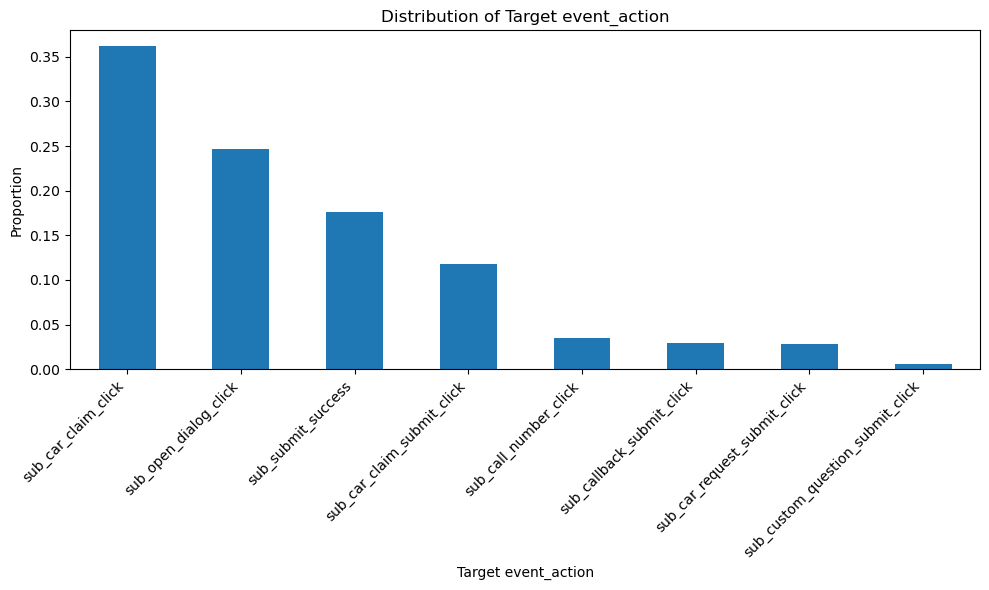

In [10]:
# Фильтруем df_hits только по целевым event_action
target_hits = df_hits[df_hits['event_action'].isin(target_actions)]

# Строим бар-график с пропорциями
target_hits['event_action'].value_counts(normalize=True).plot(
    kind='bar', 
    figsize=(10, 6), 
    title="Distribution of Target event_action"
)

# Добавляем подписи осей (опционально)
plt.xlabel("Target event_action")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha='right')  # Поворачиваем подписи для удобства
plt.tight_layout()  # Улучшает отображение графика
plt.show()

In [11]:
df_hits_agg = df_hits.groupby('session_id')['target'].max().reset_index()
df_hits_agg[df_hits_agg['target'] == 1]

,session_id,target
31,1000136488597247974.1639897063.1639897063,1
89,1000389444973162418.1621946290.1621946290,1
120,1000512929594478414.1638534989.1638534989,1
248,1001214989243294231.1638179143.1638179143,1
298,100138766161469545.1632428137.1632428137,1
...,...,...
1734552,999746093241558256.1632212924.1632212924,1
1734566,999806708110929695.1628076098.1628076098,1
1734584,999819477043134339.1621901188.1621901188,1
1734589,999869672343970659.1639949158.1639949158,1


In [12]:
df_combined = pd.merge(df_sessions, df_hits_agg, on='session_id', how='left')
df_combined

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,target
0,9055434745589932991.1637753792.1637753792,2108382700.163775,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust,0.0
1,905544597018549464.1636867290.1636867290,210838531.163687,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow,0.0
2,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk,0.0
3,9055447046360770272.1622255328.1622255328,2108385564.162225,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0.0
4,9055447046360770272.1622255345.1622255345,2108385564.162225,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,9055415581448263752.1640159305.1640159305,2108378238.164016,2021-12-22,10:48:25,1,BHcvLfOaCWvWTykYqHVe,cpc,NaN,NaN,VlqBmecIOXWjCWUmQkLd,desktop,Windows,NaN,NaN,1920x1080,Chrome,Russia,Moscow,0.0
1860038,9055421130527858185.1622007305.1622007305,2108379530.162201,2021-05-26,08:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Apple,NaN,390x844,Safari,Russia,Stavropol,0.0
1860039,9055422955903931195.1636979515.1636979515,2108379955.163698,2021-11-15,15:31:55,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,iOS,Apple,NaN,375x667,Safari,Russia,Moscow,0.0
1860040,905543020766873816.1638189404.1638189404,210838164.163819,2021-11-29,15:36:44,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,NaN,393x851,Chrome,Russia,Chelyabinsk,0.0


In [13]:
df_combined['target'] = df_combined['target'].fillna(0).astype(int)

In [14]:
df_combined

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,target
0,9055434745589932991.1637753792.1637753792,2108382700.163775,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust,0
1,905544597018549464.1636867290.1636867290,210838531.163687,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow,0
2,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk,0
3,9055447046360770272.1622255328.1622255328,2108385564.162225,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0
4,9055447046360770272.1622255345.1622255345,2108385564.162225,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,9055415581448263752.1640159305.1640159305,2108378238.164016,2021-12-22,10:48:25,1,BHcvLfOaCWvWTykYqHVe,cpc,NaN,NaN,VlqBmecIOXWjCWUmQkLd,desktop,Windows,NaN,NaN,1920x1080,Chrome,Russia,Moscow,0
1860038,9055421130527858185.1622007305.1622007305,2108379530.162201,2021-05-26,08:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Apple,NaN,390x844,Safari,Russia,Stavropol,0
1860039,9055422955903931195.1636979515.1636979515,2108379955.163698,2021-11-15,15:31:55,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,iOS,Apple,NaN,375x667,Safari,Russia,Moscow,0
1860040,905543020766873816.1638189404.1638189404,210838164.163819,2021-11-29,15:36:44,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,NaN,393x851,Chrome,Russia,Chelyabinsk,0


In [15]:
df_combined[df_combined['target'] == 1]

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,target
71,9055768928391199041.1623652678.1623652678,2108460508.162365,2021-06-14,09:00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Huawei,NaN,360x780,Chrome,Russia,Moscow,1
75,9055789093275396095.1636395007.1636395007,2108465203.16364,2021-11-08,21:10:07,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,iOS,Apple,NaN,414x736,Safari,Russia,Samara,1
78,9055794766915104430.1624305327.1624305327,2108466524.16243,2021-06-21,22:00:00,1,BHcvLfOaCWvWTykYqHVe,cpc,NaN,NaN,NaN,desktop,NaN,NaN,NaN,834x1112,Safari,Russia,Domodedovo,1
132,9056028189803556573.1630154471.1630154471,2108520872.163015,2021-08-28,15:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Samsung,NaN,412x915,YaBrowser,Russia,Krasnodar,1
142,9056093322981390023.1628944098.1628944098,2108536037.162894,2021-08-14,15:00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Samsung,NaN,360x740,Chrome,Russia,Moscow,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1859923,9054912872702758664.1636781836.1636781836,2108261192.163678,2021-11-13,08:37:16,1,kjsLglQLzykiRbcDiGcD,cpc,LwJZxKuWmvOhPsaCeRjG,NaN,HKFjmDlYppkKqsWPogJt,mobile,Android,Xiaomi,NaN,360x800,Chrome,Russia,Moscow,1
1860000,9055248417020050011.1634073188.1634073188,2108339317.163407,2021-10-13,00:00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,SgIUDYUKnyWHVowUOqid,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Huawei,NaN,360x780,Chrome,Russia,Nizhny Novgorod,1
1860002,9055248417020050011.1634075541.1634075541,2108339317.163407,2021-10-13,00:00:00,3,ZpYIoDJMcFzVoPFsHGJL,banner,SgIUDYUKnyWHVowUOqid,JNHcPlZPxEMWDnRiyoBf,NaN,mobile,NaN,Huawei,NaN,360x780,Chrome,Russia,Nizhny Novgorod,1
1860029,9055376699099939975.1630766214.1630766214,2108369185.163077,2021-09-04,17:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,NaN,desktop,NaN,NaN,NaN,1920x1080,Chrome,Russia,Khimki,1


In [16]:
df_combined.nunique(dropna=False)

session_id                  1860042
client_id                   1391717
visit_date                      226
visit_time                    85318
visit_number                    537
utm_source                      294
utm_medium                       56
utm_campaign                    413
utm_adcontent                   287
utm_keyword                    1220
device_category                   3
device_os                        14
device_brand                    206
device_model                    105
device_screen_resolution       5039
device_browser                   57
geo_country                     166
geo_city                       2548
target                            2
dtype: int64

In [17]:
def print_useful_rows_info(df):
    filled_rows = df.dropna()
    print('Количество заполненных строк:', len(filled_rows))
    print('Процент заполненных строк:', round(len(filled_rows) / len(df) * 100, 2))
    print('Количество строк с NaN:', df.isna().sum().sum())
    print('Процент строк с NaN:', round(df.isna().sum().sum() / df.size * 100, 2))

print_useful_rows_info(df_combined)

Количество заполненных строк: 14940
Процент заполненных строк: 0.8
Количество строк с NaN: 4918396
Процент строк с NaN: 13.92


In [18]:
df_combined.isna().sum().sort_values(ascending=False)

device_model                1843704
utm_keyword                 1082061
device_os                   1070138
device_brand                 367178
utm_adcontent                335615
utm_campaign                 219603
utm_source                       97
geo_city                          0
geo_country                       0
device_browser                    0
device_screen_resolution          0
session_id                        0
device_category                   0
client_id                         0
utm_medium                        0
visit_number                      0
visit_time                        0
visit_date                        0
target                            0
dtype: int64

In [19]:
df_combined['target'].value_counts(dropna=False)

target
0    1809728
1      50314
Name: count, dtype: int64

In [20]:
df_combined['device_model'].value_counts(dropna=False)

device_model
NaN                     1843704
AuMdmADEIoPXiWpTsBEj       9778
tWBQlsvNfHxRUjaPAfhd        653
cwMJxNXiWUgMUxGiCTPs        651
pTgAEPipQxDXCjPrJbHo        461
                         ...   
LDCqZZOpaddysclyNkHj          1
MBGYWAQSYWUphNxTsAWD          1
VDidzTqFGxuqiRQJGrwB          1
aWSBcBZlKorTFjJGlWKG          1
niQdLVcBlNylrEuNcCYH          1
Name: count, Length: 105, dtype: int64

In [21]:
df_combined.device_model=df_combined.device_model.fillna('other')
df_combined['device_model'].value_counts(dropna=False)

device_model
other                   1843704
AuMdmADEIoPXiWpTsBEj       9778
tWBQlsvNfHxRUjaPAfhd        653
cwMJxNXiWUgMUxGiCTPs        651
pTgAEPipQxDXCjPrJbHo        461
                         ...   
LDCqZZOpaddysclyNkHj          1
MBGYWAQSYWUphNxTsAWD          1
VDidzTqFGxuqiRQJGrwB          1
aWSBcBZlKorTFjJGlWKG          1
niQdLVcBlNylrEuNcCYH          1
Name: count, Length: 105, dtype: int64

In [22]:
df_combined['device_os'].value_counts(dropna=False)

device_os
NaN              1070138
Android           464054
iOS               207104
Windows            88307
Macintosh          24824
Linux               5120
(not set)            364
Chrome OS             83
BlackBerry            27
Tizen                  7
Samsung                4
Windows Phone          4
Firefox OS             3
Nokia                  3
Name: count, dtype: int64

In [23]:
df_combined.device_os=df_combined.device_os.fillna('other')
df_combined['device_os'].value_counts(dropna=False)

device_os
other            1070138
Android           464054
iOS               207104
Windows            88307
Macintosh          24824
Linux               5120
(not set)            364
Chrome OS             83
BlackBerry            27
Tizen                  7
Samsung                4
Windows Phone          4
Firefox OS             3
Nokia                  3
Name: count, dtype: int64

In [24]:
df_combined['device_brand'].value_counts(dropna=False)

device_brand
Apple       551088
NaN         367178
Samsung     332194
Xiaomi      288367
Huawei      185853
             ...  
Vodafone         1
Wexler           1
KingSing         1
Star             1
Opera            1
Name: count, Length: 206, dtype: int64

In [25]:
df_combined.device_brand=df_combined.device_brand.fillna('other')
df_combined['device_brand'].value_counts(dropna=False)

device_brand
Apple       551088
other       367178
Samsung     332194
Xiaomi      288367
Huawei      185853
             ...  
Vodafone         1
Wexler           1
KingSing         1
Star             1
Opera            1
Name: count, Length: 206, dtype: int64

In [26]:
df_combined['utm_keyword'].value_counts(dropna=False)

utm_keyword
NaN                     1082061
puhZPIYqKXeFPaUviSjo     506819
aXQzDWsJuGXeBXexNHjc      24241
pHqgLcdBQPSLcrTpLkdr      13767
ITfrGJNwVsHBGJMAKoct      13353
                         ...   
XsuVVTgiDIxZtndPjvDm          1
WhaUakldaAmpLumfaADO          1
nJVPLgfxsBtPAXttNVDI          1
nwKBdMZKktIQFvhZwbFe          1
fcXWTQaKfxbkBkBnzLhK          1
Name: count, Length: 1220, dtype: int64

In [27]:
#df_combined.utm_keyword=df_combined.utm_keyword.fillna('other')
#df_combined['utm_keyword'].value_counts(dropna=False)

In [28]:
df_combined['utm_adcontent'].value_counts(dropna=False)

utm_adcontent
JNHcPlZPxEMWDnRiyoBf    1006599
NaN                      335615
vCIpmpaGBnIQhyYNkXqp     181048
xhoenQgDQsgfEPYNPwKO     113072
PkybGvWbaqORmxjNunqZ      60316
                         ...   
vXARZToVDdvNhALiQtvl          1
ryswqHdLvbezpDLjokYF          1
gQEnaeQmOHisHSTEyzhp          1
PlanrlymnpCeYvUrUTVJ          1
oJivRDNIrrOckRBIKOtG          1
Name: count, Length: 287, dtype: int64

In [29]:
#df_combined.utm_adcontent=df_combined.utm_adcontent.fillna('other')
#df_combined['utm_adcontent'].value_counts(dropna=False)

In [30]:
df_combined['utm_campaign'].value_counts(dropna=False)

utm_campaign
LTuZkdKfxRGVceoWkVyg    463481
LEoPHuyFvzoNfnzGgfcd    324044
FTjNLDyTrXaWYgZymFkV    247360
NaN                     219603
gecBYcKZCPMcVYdSSzKP    134042
                         ...  
RkpOyeEPgcMBSDuHLQcj         1
pcvPxfVFaAmhwFmvIeYd         1
qPDTdivQVeflLjTYIJnG         1
MHdHrBKQwbDaRalwnlJq         1
cXxuwXPoQCvAXPHpFcZl         1
Name: count, Length: 413, dtype: int64

In [31]:
#df_combined.utm_campaign=df_combined.utm_campaign.fillna('other')
#df_combined['utm_campaign'].value_counts(dropna=False)

In [32]:
df_combined['utm_source'].value_counts(dropna=False)

utm_source
ZpYIoDJMcFzVoPFsHGJL    578290
fDLlAcSmythWSCVMvqvL    300575
kjsLglQLzykiRbcDiGcD    266354
MvfHsxITijuriZxsqZqt    186199
BHcvLfOaCWvWTykYqHVe    116320
                         ...  
GYkgJdhSxirUFPHFiYSe         1
WRHPhoRKhKxaenRCLBfo         1
tjKUGseGMhkLEzdCqBRx         1
wpmatvDuiMutnvmNVPJo         1
BellrslNBZQZaIxVFGXJ         1
Name: count, Length: 294, dtype: int64

In [33]:
#df_combined.utm_source=df_combined.utm_source.fillna('other')
#df_combined['utm_source'].value_counts(dropna=False)

In [34]:
# Список столбцов для заполнения
utm_columns = ['utm_keyword', 'utm_adcontent', 'utm_campaign', 'utm_source']

# 1. Проверка пропусков до заполнения
print("Количество пропусков до заполнения:")
print(df_combined[utm_columns].isna().sum())

# 2. Вывод моды для каждого столбца
print("\nНаиболее популярные значения (мода) для каждого столбца:")
for col in utm_columns:
    mode_value = df_combined[col].mode()[0]
    print(f"{col}: {mode_value}")

# 3. Заполнение NaN модой
for col in utm_columns:
    mode_value = df_combined[col].mode()[0]
    df_combined[col] = df_combined[col].fillna(mode_value)

# 4. Проверка пропусков после заполнения
print("\nКоличество пропусков после заполнения:")
print(df_combined[utm_columns].isna().sum())

# (Опционально) Проверка распределения значений после заполнения
for col in utm_columns:
    print(f"\nРаспределение значений в {col} после заполнения:")
    print(df_combined[col].value_counts().head(5))

Количество пропусков до заполнения:
utm_keyword      1082061
utm_adcontent     335615
utm_campaign      219603
utm_source            97
dtype: int64

Наиболее популярные значения (мода) для каждого столбца:
utm_keyword: puhZPIYqKXeFPaUviSjo
utm_adcontent: JNHcPlZPxEMWDnRiyoBf
utm_campaign: LTuZkdKfxRGVceoWkVyg
utm_source: ZpYIoDJMcFzVoPFsHGJL

Количество пропусков после заполнения:
utm_keyword      0
utm_adcontent    0
utm_campaign     0
utm_source       0
dtype: int64

Распределение значений в utm_keyword после заполнения:
utm_keyword
puhZPIYqKXeFPaUviSjo    1588880
aXQzDWsJuGXeBXexNHjc      24241
pHqgLcdBQPSLcrTpLkdr      13767
ITfrGJNwVsHBGJMAKoct      13353
hAmNSZmQkKQKAjZEGlgb      11297
Name: count, dtype: int64

Распределение значений в utm_adcontent после заполнения:
utm_adcontent
JNHcPlZPxEMWDnRiyoBf    1342214
vCIpmpaGBnIQhyYNkXqp     181048
xhoenQgDQsgfEPYNPwKO     113072
PkybGvWbaqORmxjNunqZ      60316
LLfCasrxQzJIyuldcuWy      24222
Name: count, dtype: int64

Распределение

In [35]:
df_combined.isna().sum()

session_id                  0
client_id                   0
visit_date                  0
visit_time                  0
visit_number                0
utm_source                  0
utm_medium                  0
utm_campaign                0
utm_adcontent               0
utm_keyword                 0
device_category             0
device_os                   0
device_brand                0
device_model                0
device_screen_resolution    0
device_browser              0
geo_country                 0
geo_city                    0
target                      0
dtype: int64

In [36]:
df_combined['visit_number'].value_counts(dropna=False)

visit_number
1      1376349
2       235656
3        81068
4        41666
5        24271
        ...   
419          1
420          1
421          1
422          1
564          1
Name: count, Length: 537, dtype: int64

In [37]:
# Проверить, есть ли дубликаты
duplicates = df_combined.duplicated()

# Количество дубликатов
print(f"Количество дубликатов: {duplicates.sum()}")

# Вывести дублирующиеся строки
print(df_combined[duplicates])

Количество дубликатов: 0
Empty DataFrame
Columns: [session_id, client_id, visit_date, visit_time, visit_number, utm_source, utm_medium, utm_campaign, utm_adcontent, utm_keyword, device_category, device_os, device_brand, device_model, device_screen_resolution, device_browser, geo_country, geo_city, target]
Index: []


In [38]:
df_combined

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,target
0,9055434745589932991.1637753792.1637753792,2108382700.163775,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,other,360x720,Chrome,Russia,Zlatoust,0
1,905544597018549464.1636867290.1636867290,210838531.163687,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,other,385x854,Samsung Internet,Russia,Moscow,0
2,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,other,360x720,Chrome,Russia,Krasnoyarsk,0
3,9055447046360770272.1622255328.1622255328,2108385564.162225,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,LTuZkdKfxRGVceoWkVyg,NOBKLgtuvqYWkXQHeYWM,puhZPIYqKXeFPaUviSjo,mobile,other,Xiaomi,other,393x786,Chrome,Russia,Moscow,0
4,9055447046360770272.1622255345.1622255345,2108385564.162225,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Xiaomi,other,393x786,Chrome,Russia,Moscow,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,9055415581448263752.1640159305.1640159305,2108378238.164016,2021-12-22,10:48:25,1,BHcvLfOaCWvWTykYqHVe,cpc,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,VlqBmecIOXWjCWUmQkLd,desktop,Windows,other,other,1920x1080,Chrome,Russia,Moscow,0
1860038,9055421130527858185.1622007305.1622007305,2108379530.162201,2021-05-26,08:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,390x844,Safari,Russia,Stavropol,0
1860039,9055422955903931195.1636979515.1636979515,2108379955.163698,2021-11-15,15:31:55,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,iOS,Apple,other,375x667,Safari,Russia,Moscow,0
1860040,905543020766873816.1638189404.1638189404,210838164.163819,2021-11-29,15:36:44,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,other,393x851,Chrome,Russia,Chelyabinsk,0


In [39]:
df_combined.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 19 columns):
 #   Column                    Dtype 
---  ------                    ----- 
 0   session_id                object
 1   client_id                 object
 2   visit_date                object
 3   visit_time                object
 4   visit_number              int64 
 5   utm_source                object
 6   utm_medium                object
 7   utm_campaign              object
 8   utm_adcontent             object
 9   utm_keyword               object
 10  device_category           object
 11  device_os                 object
 12  device_brand              object
 13  device_model              object
 14  device_screen_resolution  object
 15  device_browser            object
 16  geo_country               object
 17  geo_city                  object
 18  target                    int64 
dtypes: int64(2), object(17)
memory usage: 269.6+ MB


In [40]:
none_rows = df_combined[df_combined['utm_medium'] == '(none)']
none_rows

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,target
11,9055469620715506713.1628883994.1628883994,2108390820.162888,2021-08-13,22:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x869,Android Webview,Russia,Saint Petersburg,0
12,9055469620715506713.1633110583.1633110583,2108390820.162888,2021-10-01,20:00:00,2,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x869,Android Webview,Russia,Saint Petersburg,0
28,9055505230298952295.1638478433.1638478433,2108399111.163848,2021-12-02,23:53:53,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,Windows,other,other,1536x864,Chrome,Russia,Balashikha,0
29,9055507072827135870.1625692029.1625692029,2108399540.162569,2021-07-08,00:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Xiaomi,other,393x699,Chrome,Russia,Pushkino,0
30,9055507072827135870.1625694582.1625694582,2108399540.162569,2021-07-08,00:00:00,2,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Xiaomi,other,393x699,Chrome,Russia,Pushkino,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860022,9055345397369530035.1622009529.1622009529,2108361897.162201,2021-05-26,09:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,other,other,other,1536x864,Firefox,Russia,(not set),0
1860026,9055355469082180480.1636350848.1636350848,2108364242.163635,2021-11-08,08:54:08,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,other,393x873,Chrome,Russia,Moscow,0
1860029,9055376699099939975.1630766214.1630766214,2108369185.163077,2021-09-04,17:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,other,other,other,1920x1080,Chrome,Russia,Khimki,1
1860038,9055421130527858185.1622007305.1622007305,2108379530.162201,2021-05-26,08:00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,390x844,Safari,Russia,Stavropol,0


In [41]:
not_set_rows = df_combined[df_combined['device_os'] == '(not set)']
not_set_rows

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,target
2098,9064834719606978300.1640838923.1640838923,2110571302.164084,2021-12-30,07:35:23,1,fgymSoTvjKPEgaIJqsiH,cpm,FTjNLDyTrXaWYgZymFkV,yYdBRbPmBMUZHXwqGxNx,qUcotcWimEOQiboVPcCx,desktop,(not set),other,other,2048x1152,helloworld,Russia,Moscow,0
7690,9089787985673454509.1638794162.1638794162,2116381187.163879,2021-12-06,15:36:02,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,1600x20000,Chrome,(not set),(not set),0
8519,9093064959820033783.1637871353.1637871353,2117144167.163787,2021-11-25,23:15:53,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,800x600,Mozilla Compatible Agent,Iran,(not set),0
18460,9137084547786984850.1636683155.1636683155,2127393276.163668,2021-11-12,05:12:35,1,nSReTmyFtbSjlPrTKoaX,fb_smm,dZqEgyoxhtbeLFMtnnVR,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,2000x2000,Instagram 213.0.0.29.120 Android,United States,Prineville,0
25276,916696286332639165.1640421309.1640421309,213434986.164042,2021-12-25,11:35:09,1,QxAxdyPLuQMEcrdZWdWb,cpa,mSVMBvlHFgftJaQAZEdp,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,2000x2000,Instagram 216.1.0.21.137 Android,United States,Forest City,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1836833,8952294176877949991.1637594154.1637594154,2084368415.163759,2021-11-22,18:15:54,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,1600x20000,Chrome,(not set),(not set),0
1836849,895236623968478102.1636803482.1636803482,208438519.16368,2021-11-13,14:38:02,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,2000x2000,Instagram 212.0.0.38.119 Android,United States,Prineville,0
1844872,8986869591324785379.1638693606.1638693606,2092418631.163869,2021-12-05,11:40:06,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,800x600,Mozilla Compatible Agent,Russia,Saint Petersburg,0
1845353,8988891541668420845.1638456556.1638456564,2092889403.163846,2021-12-02,17:49:24,1,bByPQxmDaMXgpHeypKSM,referral,mSVMBvlHFgftJaQAZEdp,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,(not set),other,other,2000x2000,(not set),United States,Forest City,0


## Типы данных и визуализация, удаление выбросов

In [43]:
df_combined['visit_date'] = pd.to_datetime(df_combined['visit_date'],format='%Y-%m-%d', utc=True)
df_combined['visit_time'] = pd.to_datetime(df_combined['visit_time'],format='%H:%M:%S', utc=True)
df_combined.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 19 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   session_id                object             
 1   client_id                 object             
 2   visit_date                datetime64[ns, UTC]
 3   visit_time                datetime64[ns, UTC]
 4   visit_number              int64              
 5   utm_source                object             
 6   utm_medium                object             
 7   utm_campaign              object             
 8   utm_adcontent             object             
 9   utm_keyword               object             
 10  device_category           object             
 11  device_os                 object             
 12  device_brand              object             
 13  device_model              object             
 14  device_screen_resolution  object             
 15  device_browser 

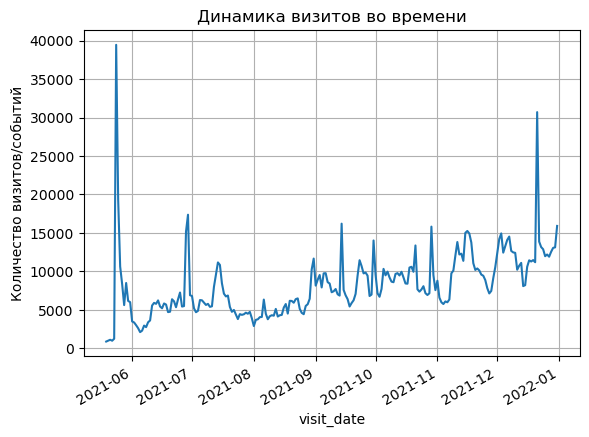

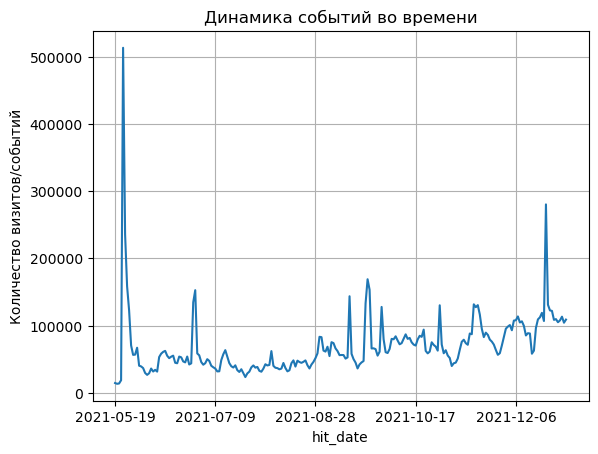

In [44]:
def plot_visits_over_time(df, column, title):
    df[column].value_counts().sort_index().plot(kind='line')
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel("Количество визитов/событий")
    plt.grid(True)
    plt.show()

plot_visits_over_time(df_combined, "visit_date", "Динамика визитов во времени")
plot_visits_over_time(df_hits, "hit_date", "Динамика событий во времени")

In [45]:
df_combined['visit_date'].value_counts(dropna=False)

visit_date
2021-05-24 00:00:00+00:00    39453
2021-12-21 00:00:00+00:00    30704
2021-05-25 00:00:00+00:00    19305
2021-06-29 00:00:00+00:00    17367
2021-09-14 00:00:00+00:00    16204
                             ...  
2021-06-05 00:00:00+00:00     2102
2021-05-23 00:00:00+00:00     1246
2021-05-21 00:00:00+00:00     1110
2021-05-22 00:00:00+00:00      986
2021-05-19 00:00:00+00:00      877
Name: count, Length: 226, dtype: int64

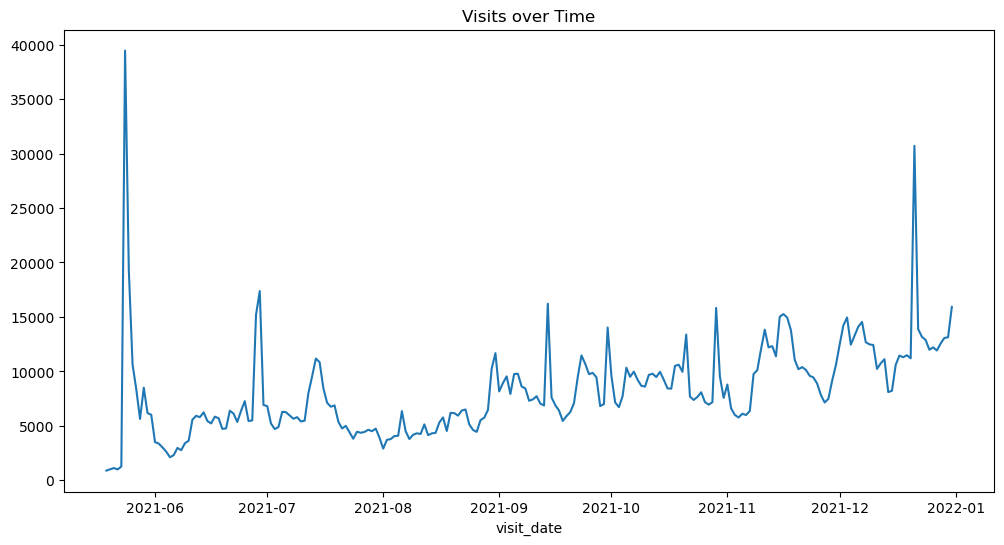

In [46]:
#Распределение visit_date по дням
df_combined['visit_date'].dt.date.value_counts().sort_index().plot(kind='line', figsize=(12, 6))
plt.title('Visits over Time')
plt.show()

In [47]:
# Группируем по дате и считаем количество визитов
visit_counts = df_combined.groupby('visit_date')['visit_date'].count()
visit_counts.name = 'count'
visit_counts = visit_counts.reset_index()


# Вычисляем IQR
Q1 = visit_counts['count'].quantile(0.25)
Q3 = visit_counts['count'].quantile(0.75)
IQR = Q3 - Q1

# Определяем границы
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Выделяем выбросы
outliers = visit_counts[(visit_counts['count'] < lower_bound) | (visit_counts['count'] > upper_bound)]
normal_data = visit_counts[(visit_counts['count'] >= lower_bound) & (visit_counts['count'] <= upper_bound)]
# Выводим дни и значения выбросов
print(outliers[['visit_date', 'count']])


                   visit_date  count
4   2021-05-24 00:00:00+00:00  39453
5   2021-05-25 00:00:00+00:00  19305
215 2021-12-21 00:00:00+00:00  30704


/var/folders/p0/ykk516gx4yl4sg0c64v939gh0000gn/T/ipykernel_5113/2625291957.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_combined['day'] = df_combined['visit_date'].dt.to_period('D')


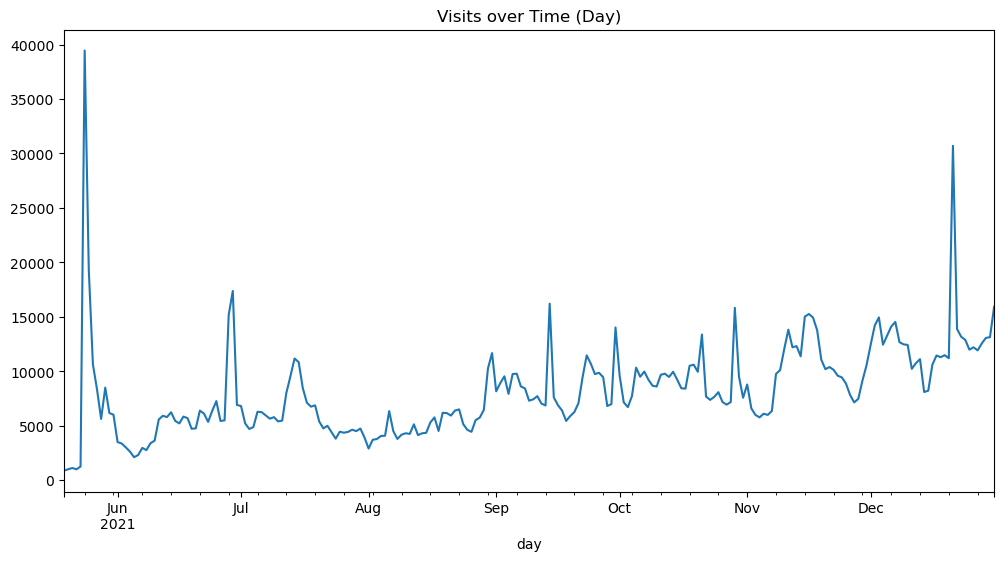

count      226.000000
mean      8230.274336
std       4311.557692
min        877.000000
25%       5467.250000
50%       7326.000000
75%      10309.000000
max      39453.000000
Name: count, dtype: float64
day
2021-05-24    39453
2021-12-21    30704
Freq: D, Name: count, dtype: int64


In [48]:
# Группируем данные по году и месяцу, чтобы найти аномалии
df_combined['day'] = df_combined['visit_date'].dt.to_period('D')

# Считаем количество визитов в каждом дне
visit_counts = df_combined['day'].value_counts().sort_index()

# Строим график
visit_counts.plot(kind='line', figsize=(12, 6))
plt.title('Visits over Time (Day)')
plt.show()

# Выводим статистику по количеству визитов по дням
print(visit_counts.describe())

# Найдем выбросы на основе количества визитов (например, если количество визитов значительно выше среднего)
mean_visits = visit_counts.mean()
std_visits = visit_counts.std()

# Определяем, что считать выбросами (например, 3 стандартных отклонения от среднего)
outliers = visit_counts[visit_counts > mean_visits + 3 * std_visits]

# Показываем выбросы
print(outliers)

In [49]:
outliers_days = outliers.index

df_filtered = df_combined[~df_combined['day'].isin(outliers_days)]

df_filtered

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,target,day
0,9055434745589932991.1637753792.1637753792,2108382700.163775,2021-11-24 00:00:00+00:00,1900-01-01 14:36:32+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,other,360x720,Chrome,Russia,Zlatoust,0,2021-11-24
1,905544597018549464.1636867290.1636867290,210838531.163687,2021-11-14 00:00:00+00:00,1900-01-01 08:21:30+00:00,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,other,385x854,Samsung Internet,Russia,Moscow,0,2021-11-14
2,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28 00:00:00+00:00,1900-01-01 02:42:06+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,other,360x720,Chrome,Russia,Krasnoyarsk,0,2021-12-28
3,9055447046360770272.1622255328.1622255328,2108385564.162225,2021-05-29 00:00:00+00:00,1900-01-01 05:00:00+00:00,1,kjsLglQLzykiRbcDiGcD,cpc,LTuZkdKfxRGVceoWkVyg,NOBKLgtuvqYWkXQHeYWM,puhZPIYqKXeFPaUviSjo,mobile,other,Xiaomi,other,393x786,Chrome,Russia,Moscow,0,2021-05-29
4,9055447046360770272.1622255345.1622255345,2108385564.162225,2021-05-29 00:00:00+00:00,1900-01-01 05:00:00+00:00,2,kjsLglQLzykiRbcDiGcD,cpc,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Xiaomi,other,393x786,Chrome,Russia,Moscow,0,2021-05-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860037,9055415581448263752.1640159305.1640159305,2108378238.164016,2021-12-22 00:00:00+00:00,1900-01-01 10:48:25+00:00,1,BHcvLfOaCWvWTykYqHVe,cpc,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,VlqBmecIOXWjCWUmQkLd,desktop,Windows,other,other,1920x1080,Chrome,Russia,Moscow,0,2021-12-22
1860038,9055421130527858185.1622007305.1622007305,2108379530.162201,2021-05-26 00:00:00+00:00,1900-01-01 08:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,390x844,Safari,Russia,Stavropol,0,2021-05-26
1860039,9055422955903931195.1636979515.1636979515,2108379955.163698,2021-11-15 00:00:00+00:00,1900-01-01 15:31:55+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,iOS,Apple,other,375x667,Safari,Russia,Moscow,0,2021-11-15
1860040,905543020766873816.1638189404.1638189404,210838164.163819,2021-11-29 00:00:00+00:00,1900-01-01 15:36:44+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,other,393x851,Chrome,Russia,Chelyabinsk,0,2021-11-29


/var/folders/p0/ykk516gx4yl4sg0c64v939gh0000gn/T/ipykernel_5113/654823739.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_filtered['day'] = df_filtered['visit_date'].dt.to_period('D')
/var/folders/p0/ykk516gx4yl4sg0c64v939gh0000gn/T/ipykernel_5113/654823739.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['day'] = df_filtered['visit_date'].dt.to_period('D')


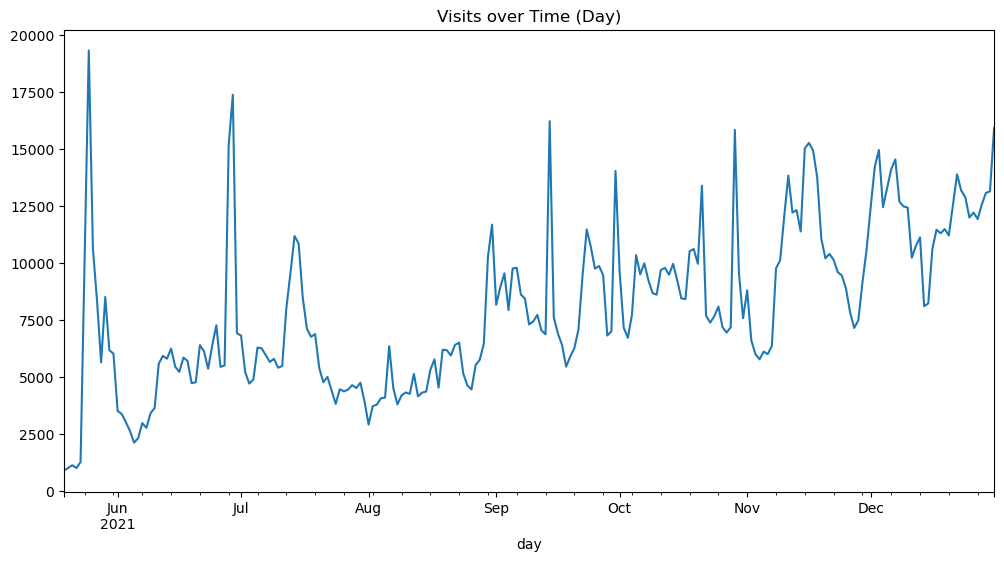

count      224.000000
mean      7990.558036
std       3473.051495
min        877.000000
25%       5454.500000
50%       7269.500000
75%      10225.000000
max      19305.000000
Name: count, dtype: float64
day
2021-05-25    19305
Freq: D, Name: count, dtype: int64


In [50]:
# Группируем данные по году и месяцу, чтобы найти аномалии
df_filtered['day'] = df_filtered['visit_date'].dt.to_period('D')

# Считаем количество визитов в каждом дне
visit_counts = df_filtered['day'].value_counts().sort_index()

# Строим график
visit_counts.plot(kind='line', figsize=(12, 6))
plt.title('Visits over Time (Day)')
plt.show()

# Выводим статистику по количеству визитов по дням
print(visit_counts.describe())

# Найдем выбросы на основе количества визитов (например, если количество визитов значительно выше среднего)
mean_visits = visit_counts.mean()
std_visits = visit_counts.std()

# Определяем, что считать выбросами (например, 3 стандартных отклонения от среднего)
outliers = visit_counts[visit_counts > mean_visits + 3 * std_visits]

# Показываем выбросы
print(outliers)

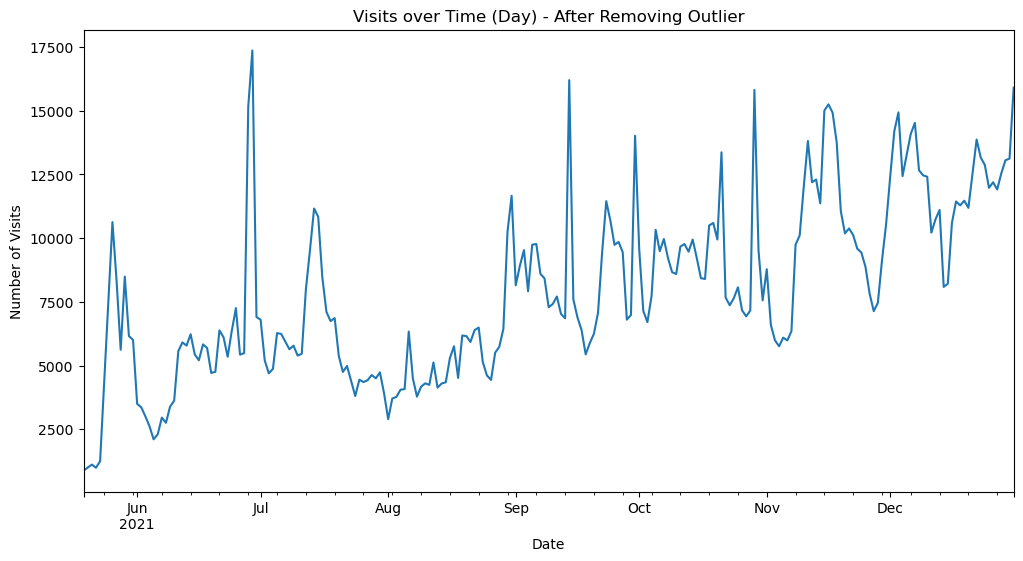

Статистика количества визитов по дням после удаления выброса:
count      223.000000
mean      7939.820628
std       3396.642930
min        877.000000
25%       5448.000000
50%       7252.000000
75%      10202.000000
max      17367.000000
Name: count, dtype: float64

Оставшиеся выбросы (если есть):
Нет выбросов


In [51]:
# 1. Удаление строк с выбросом (day == '2021-05-25')
outlier_day = pd.Period('2021-05-25', freq='D')
df_filtered = df_filtered[df_filtered['day'] != outlier_day]

# 2. Проверка результата: пересчет количества визитов по дням
visit_counts = df_filtered['day'].value_counts().sort_index()

# Построение графика после удаления выброса
plt.figure(figsize=(12, 6))
visit_counts.plot(kind='line')
plt.title('Visits over Time (Day) - After Removing Outlier')
plt.xlabel('Date')
plt.ylabel('Number of Visits')
plt.show()

# Вывод статистики после удаления выброса
print("Статистика количества визитов по дням после удаления выброса:")
print(visit_counts.describe())

# Проверка, остались ли выбросы
mean_visits = visit_counts.mean()
std_visits = visit_counts.std()
outliers = visit_counts[visit_counts > mean_visits + 3 * std_visits]
print("\nОставшиеся выбросы (если есть):")
print(outliers if not outliers.empty else "Нет выбросов")

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


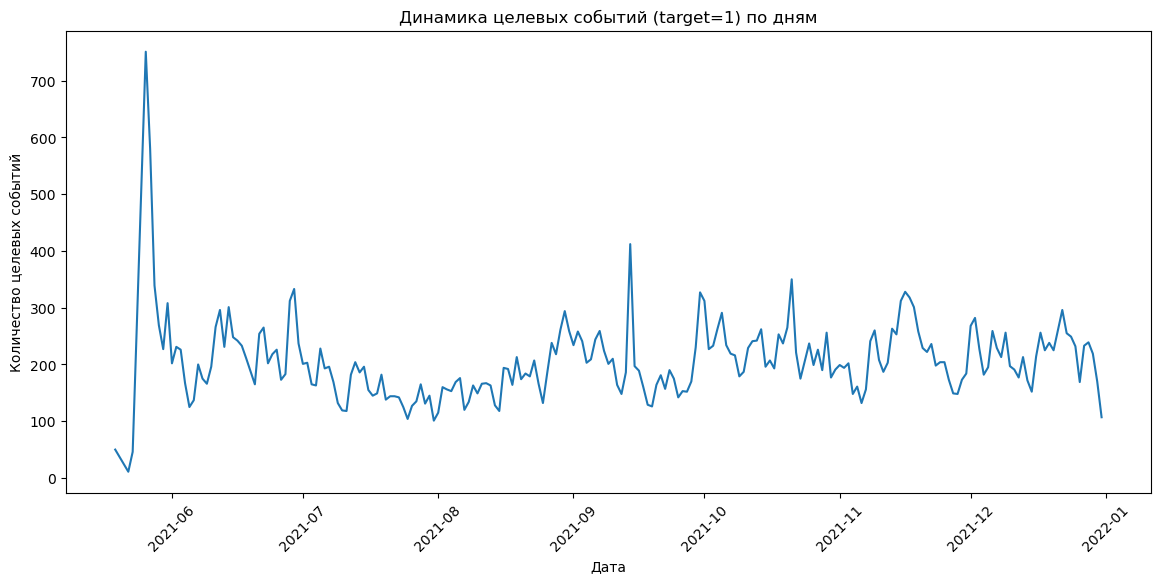

In [52]:
# Динамика целевых событий (target=1) по дням
target_counts = df_filtered[df_filtered['target'] == 1].groupby('visit_date').size().reset_index(name='target_count')
plt.figure(figsize=(14, 6))
sns.lineplot(data=target_counts, x='visit_date', y='target_count')
plt.title('Динамика целевых событий (target=1) по дням')
plt.xlabel('Дата')
plt.ylabel('Количество целевых событий')
plt.xticks(rotation=45)
plt.show()


In [53]:
target_counts = df_filtered[df_filtered['target'] == 1].groupby('visit_date').size().reset_index(name='target_count')

# Статистика для определения выбросов
mean_target_count = target_counts['target_count'].mean()
std_target_count = target_counts['target_count'].std()

# Определение аномалий (больше mean + 3 * std)
outliers = target_counts[target_counts['target_count'] > mean_target_count + 3 * std_target_count]
print("Аномальные дни с высоким количеством целевых событий:")
print(outliers)

Аномальные дни с высоким количеством целевых событий:
                 visit_date  target_count
3 2021-05-26 00:00:00+00:00           751
4 2021-05-27 00:00:00+00:00           580


In [54]:
max_target_day = target_counts.loc[target_counts['target_count'].idxmax()]
print("\nДень с максимальным количеством целевых событий:")
print(max_target_day)

# 2. Показ данных за аномальный день
# Предположим, аномальный день — это max_target_day['visit_date']
anomaly_date = max_target_day['visit_date']
anomaly_data = df_filtered[(df_filtered['visit_date'] == anomaly_date) & (df_filtered['target'] == 1)]

print(f"\nДанные за аномальный день ({anomaly_date.date()}):")
print(anomaly_data[['utm_source', 'utm_medium', 'utm_campaign', 'geo_city', 'device_category', 'target']])
print(f"\nКоличество строк за {anomaly_date.date()}: {len(anomaly_data)}")

# (Опционально) Анализ распределения ключевых признаков
print("\nРаспределение utm_medium за аномальный день:")
print(anomaly_data['utm_medium'].value_counts())


День с максимальным количеством целевых событий:
visit_date      2021-05-26 00:00:00+00:00
target_count                          751
Name: 3, dtype: object

Данные за аномальный день (2021-05-26):
                   utm_source utm_medium          utm_campaign       geo_city  \
1936     fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg         Moscow   
4273     fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg         Moscow   
10334    DnEUulZAecfGPvdtZBYS   referral  LTuZkdKfxRGVceoWkVyg         Moscow   
11394    aXQzDWsJuGXeBXexNHjc   referral  LTuZkdKfxRGVceoWkVyg         Moscow   
11404    fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg          Anapa   
...                       ...        ...                   ...            ...   
1839982  fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg         Moscow   
1845524  bByPQxmDaMXgpHeypKSM   referral  LTuZkdKfxRGVceoWkVyg         Tyumen   
1845854  BHcvLfOaCWvWTykYqHVe    organic  LTuZkdKfxRGVceoWkVyg         Mo

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


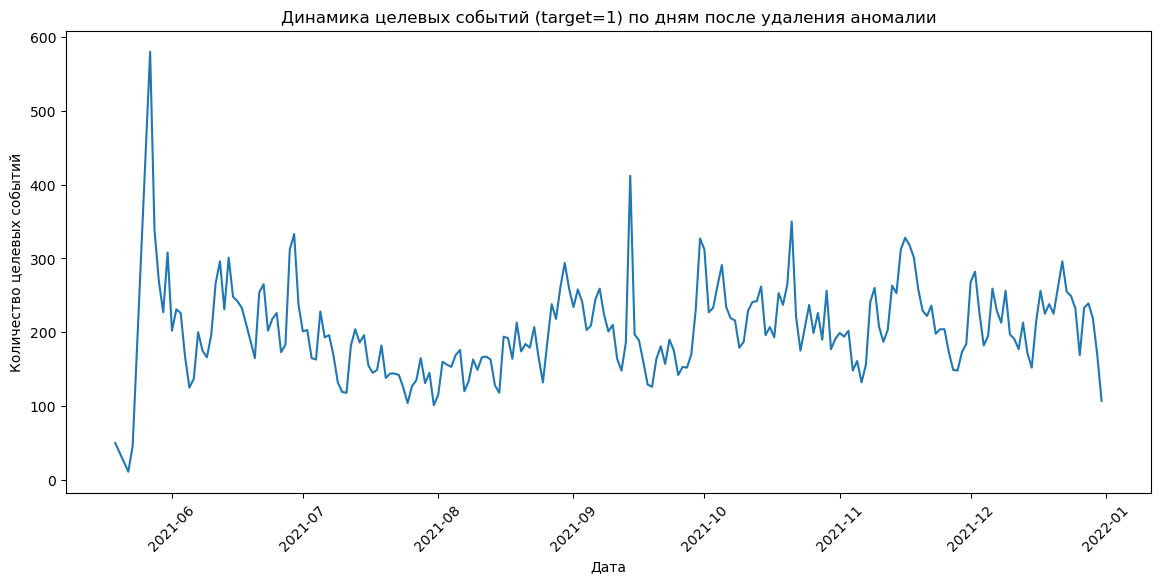


Статистика целевых событий после удаления аномалии:
count    221.000000
mean     203.425339
std       61.526566
min       11.000000
25%      165.000000
50%      198.000000
75%      236.000000
max      580.000000
Name: target_count, dtype: float64

Оставшиеся аномалии (если есть):
                   visit_date  target_count
3   2021-05-27 00:00:00+00:00           580
113 2021-09-14 00:00:00+00:00           412


In [55]:
# 3. Удаление строк за аномальный день
df_filtered = df_filtered[df_filtered['visit_date'] != anomaly_date]

# Проверка результата: пересчет динамики целевых событий
target_counts_new = df_filtered[df_filtered['target'] == 1].groupby('visit_date').size().reset_index(name='target_count')
plt.figure(figsize=(14, 6))
sns.lineplot(data=target_counts_new, x='visit_date', y='target_count')
plt.title('Динамика целевых событий (target=1) по дням после удаления аномалии')
plt.xlabel('Дата')
plt.ylabel('Количество целевых событий')
plt.xticks(rotation=45)
plt.show()

# Новая статистика
print("\nСтатистика целевых событий после удаления аномалии:")
print(target_counts_new['target_count'].describe())

# Проверка оставшихся аномалий
mean_target_count_new = target_counts_new['target_count'].mean()
std_target_count_new = target_counts_new['target_count'].std()
outliers_new = target_counts_new[target_counts_new['target_count'] > mean_target_count_new + 3 * std_target_count_new]
print("\nОставшиеся аномалии (если есть):")
print(outliers_new if not outliers_new.empty else "Нет аномалий")

оставшиеся аномалии не будем удалять, иначе у нас не останется совсем примеров положительных целевых значений

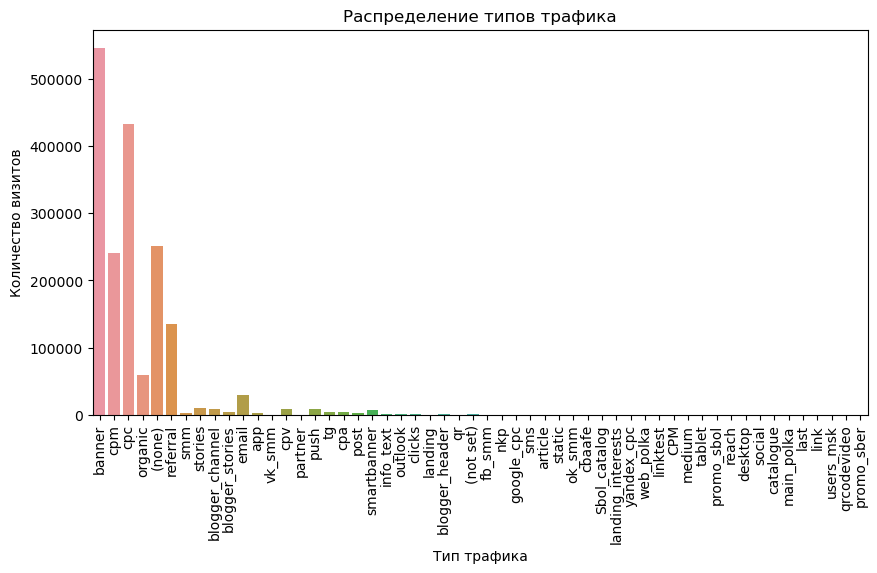

In [57]:
plt.figure(figsize=(10, 5))
sns.countplot(x="utm_medium", data=df_filtered)
plt.title("Распределение типов трафика")
plt.xlabel("Тип трафика")
plt.xticks(rotation=90)
plt.ylabel("Количество визитов")
plt.show()

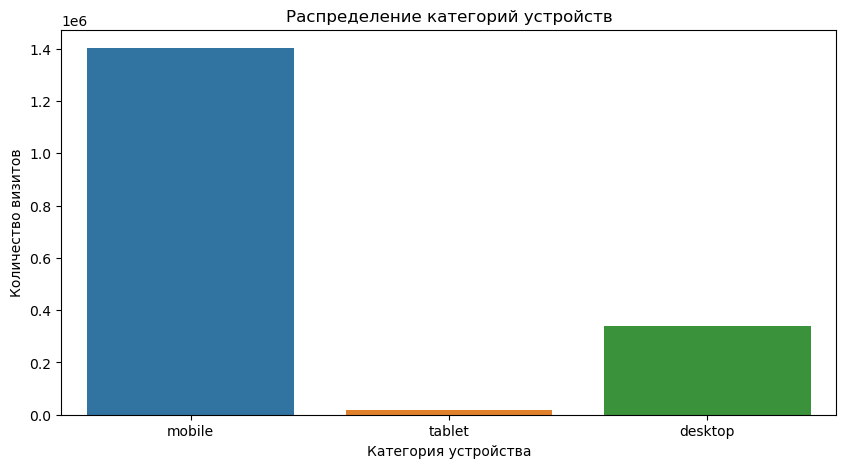

In [58]:
plt.figure(figsize=(10, 5))
sns.countplot(x="device_category", data=df_filtered)
plt.title("Распределение категорий устройств")
plt.xlabel("Категория устройства")
plt.ylabel("Количество визитов")
plt.show()

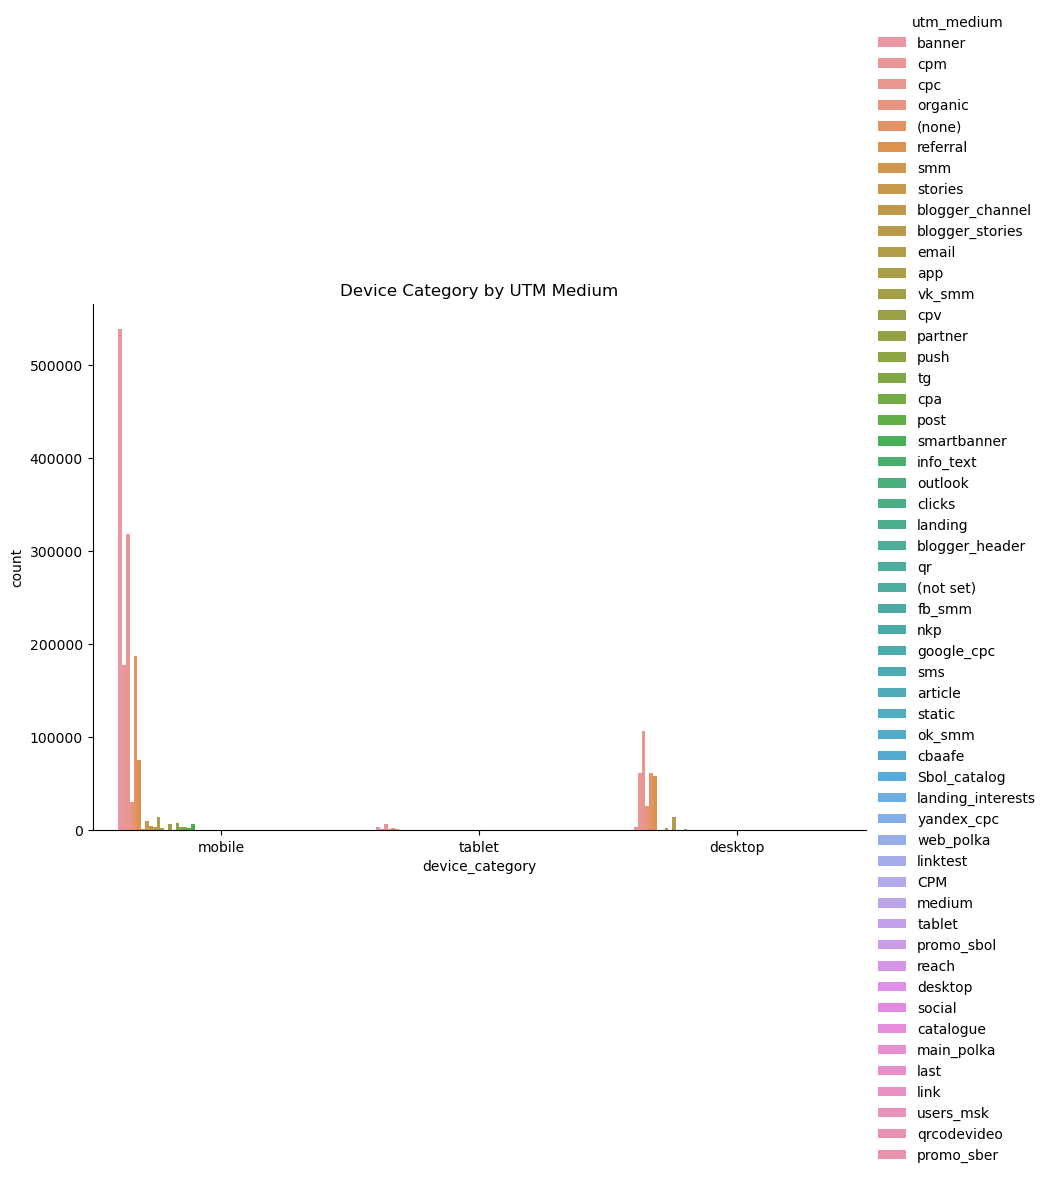

In [59]:
sns.catplot(data=df_filtered, x='device_category', hue='utm_medium', kind='count', height=6, aspect=1.5)
plt.title('Device Category by UTM Medium')
plt.show()

на мобильных устройствах больше просматриваются баннеры, а на десктопах - cpc

In [61]:
# Фильтруем строки, где utm_medium == '(none)'
filtered_data = df_filtered[df_filtered['utm_medium'] == '(none)']

# Выводим уникальные значения visit_date для этих строк
print(filtered_data['visit_date'].unique())

<DatetimeArray>
['2021-08-13 00:00:00+00:00', '2021-10-01 00:00:00+00:00',
 '2021-12-02 00:00:00+00:00', '2021-07-08 00:00:00+00:00',
 '2021-08-08 00:00:00+00:00', '2021-06-01 00:00:00+00:00',
 '2021-10-27 00:00:00+00:00', '2021-11-15 00:00:00+00:00',
 '2021-07-11 00:00:00+00:00', '2021-07-19 00:00:00+00:00',
 ...
 '2021-12-08 00:00:00+00:00', '2021-07-24 00:00:00+00:00',
 '2021-12-22 00:00:00+00:00', '2021-06-11 00:00:00+00:00',
 '2021-12-13 00:00:00+00:00', '2021-11-26 00:00:00+00:00',
 '2021-10-22 00:00:00+00:00', '2021-08-09 00:00:00+00:00',
 '2021-12-11 00:00:00+00:00', '2021-11-05 00:00:00+00:00']
Length: 222, dtype: datetime64[ns, UTC]


In [62]:
# Считаем количество строк, где utm_medium == '(none)'
count_none = df_filtered[df_filtered['utm_medium'] == '(none)'].shape[0]

# Считаем общее количество строк в DataFrame
total_count = df_filtered.shape[0]

# Рассчитываем процент
percentage_none = (count_none / total_count) * 100

# Выводим процент
print(f"Процент строк с utm_medium == '(none)': {percentage_none:.2f}%")


Процент строк с utm_medium == '(none)': 14.28%


In [63]:
df_filtered[df_filtered['utm_medium'] == '(none)']

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,target,day
11,9055469620715506713.1628883994.1628883994,2108390820.162888,2021-08-13 00:00:00+00:00,1900-01-01 22:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x869,Android Webview,Russia,Saint Petersburg,0,2021-08-13
12,9055469620715506713.1633110583.1633110583,2108390820.162888,2021-10-01 00:00:00+00:00,1900-01-01 20:00:00+00:00,2,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Samsung,other,412x869,Android Webview,Russia,Saint Petersburg,0,2021-10-01
28,9055505230298952295.1638478433.1638478433,2108399111.163848,2021-12-02 00:00:00+00:00,1900-01-01 23:53:53+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,Windows,other,other,1536x864,Chrome,Russia,Balashikha,0,2021-12-02
29,9055507072827135870.1625692029.1625692029,2108399540.162569,2021-07-08 00:00:00+00:00,1900-01-01 00:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Xiaomi,other,393x699,Chrome,Russia,Pushkino,0,2021-07-08
30,9055507072827135870.1625694582.1625694582,2108399540.162569,2021-07-08 00:00:00+00:00,1900-01-01 00:00:00+00:00,2,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Xiaomi,other,393x699,Chrome,Russia,Pushkino,0,2021-07-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860016,905532652706692816.1629060816.1629060816,210835750.162906,2021-08-15 00:00:00+00:00,1900-01-01 23:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,428x926,Safari (in-app),Russia,Moscow,0,2021-08-15
1860017,905532652706692816.1629091708.1629091708,210835750.162906,2021-08-16 00:00:00+00:00,1900-01-01 08:00:00+00:00,2,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,other,Apple,other,428x926,Safari (in-app),Russia,Moscow,0,2021-08-16
1860026,9055355469082180480.1636350848.1636350848,2108364242.163635,2021-11-08 00:00:00+00:00,1900-01-01 08:54:08+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,mobile,Android,Xiaomi,other,393x873,Chrome,Russia,Moscow,0,2021-11-08
1860029,9055376699099939975.1630766214.1630766214,2108369185.163077,2021-09-04 00:00:00+00:00,1900-01-01 17:00:00+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,desktop,other,other,other,1920x1080,Chrome,Russia,Khimki,1,2021-09-04


In [64]:
df_source = df_filtered[df_filtered['utm_source'] == 'fDLlAcSmythWSCVMvqvL']

columns_of_interest = ['utm_medium', 'utm_campaign', 'utm_adcontent']
for column in columns_of_interest:
    unique_values = df_source[column].unique()
    print(f"Уникальные значения в столбце '{column}':")
    print(unique_values)
    print("-" * 50)

Уникальные значения в столбце 'utm_medium':
['(none)']
--------------------------------------------------
Уникальные значения в столбце 'utm_campaign':
['LTuZkdKfxRGVceoWkVyg']
--------------------------------------------------
Уникальные значения в столбце 'utm_adcontent':
['JNHcPlZPxEMWDnRiyoBf']
--------------------------------------------------


тк (none) относится к конкретным utm_source utm_campaign utm_adcontent - будем считать ее отдельным значчением и не заменять на самое популярное значение

In [66]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1759949 entries, 0 to 1860041
Data columns (total 20 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   session_id                object             
 1   client_id                 object             
 2   visit_date                datetime64[ns, UTC]
 3   visit_time                datetime64[ns, UTC]
 4   visit_number              int64              
 5   utm_source                object             
 6   utm_medium                object             
 7   utm_campaign              object             
 8   utm_adcontent             object             
 9   utm_keyword               object             
 10  device_category           object             
 11  device_os                 object             
 12  device_brand              object             
 13  device_model              object             
 14  device_screen_resolution  object             
 15  device_browser      

In [67]:
df_filtered.describe()

,visit_number,target
count,1.759949e+06,1.759949e+06
mean,2.766968e+00,2.554449e-02
std,1.200928e+01,1.577719e-01
min,1.000000e+00,0.000000e+00
25%,1.000000e+00,0.000000e+00
50%,1.000000e+00,0.000000e+00
75%,2.000000e+00,0.000000e+00
max,5.640000e+02,1.000000e+00


In [68]:
df_filtered['geo_country'].value_counts(dropna=False)

geo_country
Russia                 1703826
United States            11453
Ukraine                   8495
Ireland                   4023
Belarus                   3461
                        ...   
Chad                         1
North Korea                  1
Barbados                     1
Zambia                       1
Congo - Brazzaville          1
Name: count, Length: 164, dtype: int64

In [69]:
df_filtered['geo_city'].value_counts(dropna=False)

geo_city
Moscow              754508
Saint Petersburg    281601
(not set)            75124
Yekaterinburg        33990
Krasnodar            30867
                     ...  
Novovolynsk              1
Nagano                   1
Ilza                     1
Oldbury                  1
Meerut                   1
Name: count, Length: 2464, dtype: int64

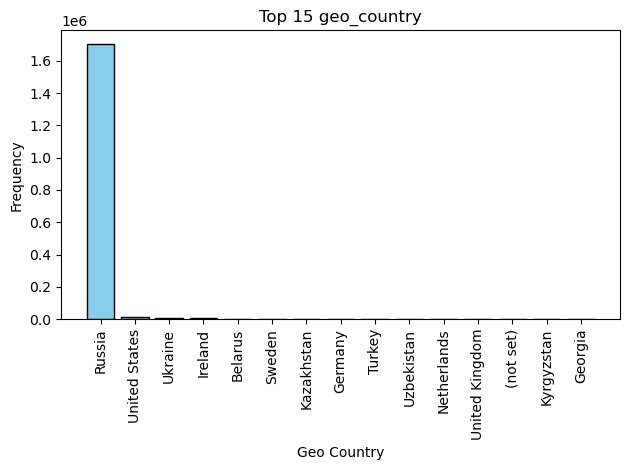

In [70]:
top_15_countries = df_filtered['geo_country'].value_counts().head(15)

# Построение гистограммы
plt.bar(top_15_countries.index, top_15_countries.values, color='skyblue', edgecolor='black')
plt.title('Top 15 geo_country')
plt.xlabel('Geo Country')
plt.ylabel('Frequency')
plt.xticks(rotation=90)  # Поворот подписей оси X для лучшей читаемости
plt.tight_layout()  # Чтобы график не обрезался
plt.show()

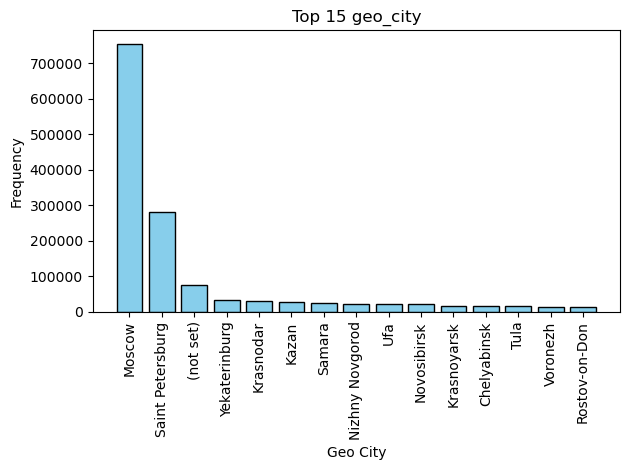

In [71]:
top_15_cities = df_filtered['geo_city'].value_counts().head(15)

# Построение гистограммы
plt.bar(top_15_cities.index, top_15_cities.values, color='skyblue', edgecolor='black')
plt.title('Top 15 geo_city')
plt.xlabel('Geo City')
plt.ylabel('Frequency')
plt.xticks(rotation=90)  # Поворот подписей оси X для лучшей читаемости
plt.tight_layout()  # Чтобы график не обрезался
plt.show()

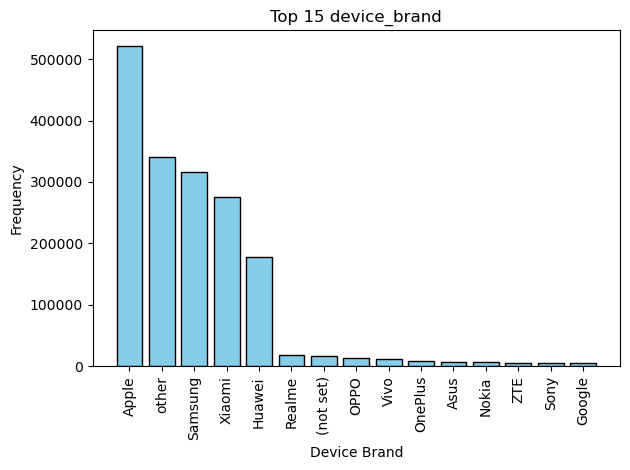

In [72]:
top_15_device_brand = df_filtered['device_brand'].value_counts().head(15)

# Построение гистограммы
plt.bar(top_15_device_brand.index, top_15_device_brand.values, color='skyblue', edgecolor='black')
plt.title('Top 15 device_brand')
plt.xlabel('Device Brand')
plt.ylabel('Frequency')
plt.xticks(rotation=90)  # Поворот подписей оси X для лучшей читаемости
plt.tight_layout()  # Чтобы график не обрезался
plt.show()

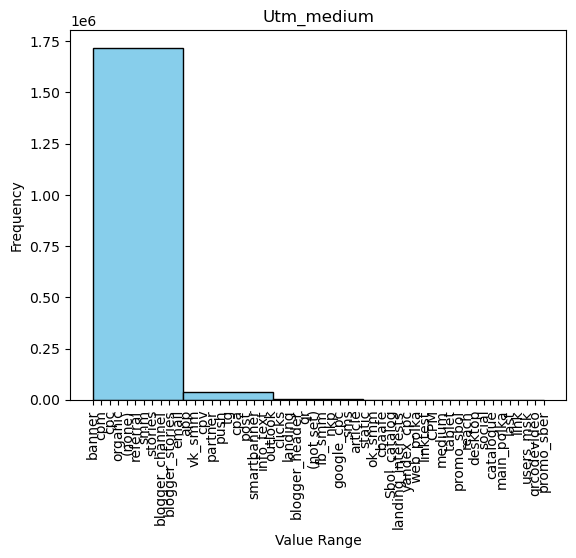

In [73]:
plt.hist(data = df_filtered, x = 'utm_medium', bins=5, color='skyblue', edgecolor='black')
plt.title('Utm_medium')
plt.xlabel('Value Range')
plt.xticks(rotation=90)
plt.ylabel('Frequency')
plt.show()

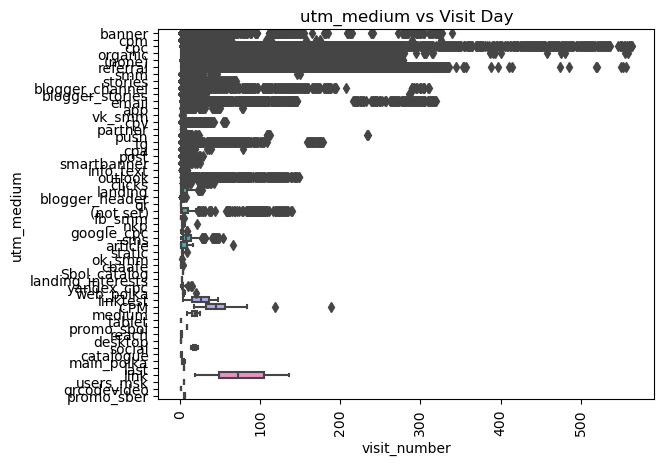

In [74]:
sns.boxplot(data=df_filtered, x='visit_number', y=df_filtered['utm_medium'])
plt.title('utm_medium vs Visit Day')
plt.xticks(rotation=90)  # Поворачиваем метки на оси X на 90 градусов
plt.show()

In [75]:
# Удаление колонки day
df_filtered = df_filtered.drop(columns=['day'])

# Проверяем результат
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1759949 entries, 0 to 1860041
Data columns (total 19 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   session_id                object             
 1   client_id                 object             
 2   visit_date                datetime64[ns, UTC]
 3   visit_time                datetime64[ns, UTC]
 4   visit_number              int64              
 5   utm_source                object             
 6   utm_medium                object             
 7   utm_campaign              object             
 8   utm_adcontent             object             
 9   utm_keyword               object             
 10  device_category           object             
 11  device_os                 object             
 12  device_brand              object             
 13  device_model              object             
 14  device_screen_resolution  object             
 15  device_browser      

In [76]:
# Извлекаем только время из visit_time
df_filtered['time_only'] = df_filtered['visit_time'].dt.time

# Создаем функцию для определения временного интервала
def get_time_period(hour):
    if 5 <= hour < 12:
        return 'morning'
    elif 12 <= hour < 17:
        return 'day'
    elif 17 <= hour < 22:
        return 'evening'
    else:
        return 'night'

# Добавляем новую колонку с обозначением временного интервала
df_filtered['time_period'] = df_filtered['visit_time'].dt.hour.apply(get_time_period)

# Проверяем результат
print(df_filtered[['visit_time', 'time_only', 'time_period']].head())


                 visit_time time_only time_period
0 1900-01-01 14:36:32+00:00  14:36:32         day
1 1900-01-01 08:21:30+00:00  08:21:30     morning
2 1900-01-01 02:42:06+00:00  02:42:06       night
3 1900-01-01 05:00:00+00:00  05:00:00     morning
4 1900-01-01 05:00:00+00:00  05:00:00     morning


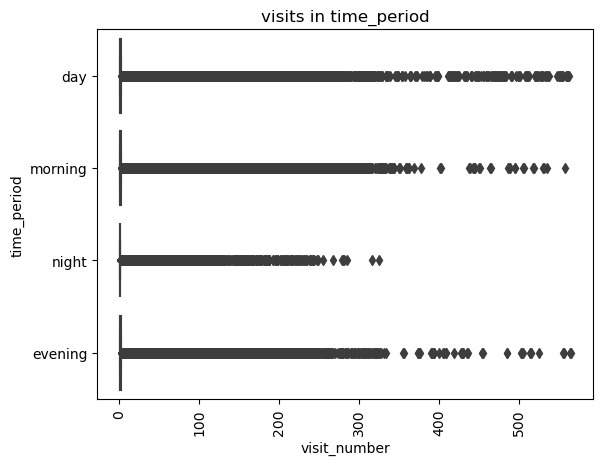

In [77]:
sns.boxplot(data=df_filtered, x='visit_number', y=df_filtered['time_period'])
plt.title('visits in time_period')
plt.xticks(rotation=90)  # Поворачиваем метки на оси X на 90 градусов
plt.show()

In [78]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1759949 entries, 0 to 1860041
Data columns (total 21 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   session_id                object             
 1   client_id                 object             
 2   visit_date                datetime64[ns, UTC]
 3   visit_time                datetime64[ns, UTC]
 4   visit_number              int64              
 5   utm_source                object             
 6   utm_medium                object             
 7   utm_campaign              object             
 8   utm_adcontent             object             
 9   utm_keyword               object             
 10  device_category           object             
 11  device_os                 object             
 12  device_brand              object             
 13  device_model              object             
 14  device_screen_resolution  object             
 15  device_browser      

In [79]:
# Создаём новую колонку с названием дня недели
df_filtered['day_of_week'] = df_filtered['visit_date'].dt.day_name()

# Проверяем результат
print(df_filtered[['visit_date', 'day_of_week']].head())


                 visit_date day_of_week
0 2021-11-24 00:00:00+00:00   Wednesday
1 2021-11-14 00:00:00+00:00      Sunday
2 2021-12-28 00:00:00+00:00     Tuesday
3 2021-05-29 00:00:00+00:00    Saturday
4 2021-05-29 00:00:00+00:00    Saturday


/opt/anaconda3/lib/python3.11/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


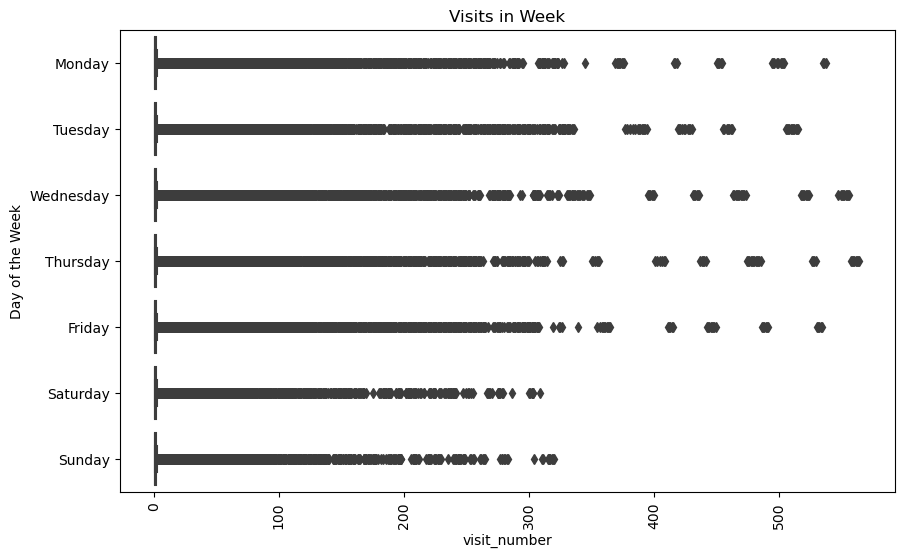

In [80]:
# Устанавливаем порядок дней недели
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Преобразуем столбец day_of_week в категориальный тип с заданным порядком
df_filtered['day_of_week'] = pd.Categorical(df_filtered['day_of_week'], categories=days_order, ordered=True)

# Создаём boxplot с упорядоченными днями недели
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_filtered, x='visit_number', y='day_of_week')
plt.title('Visits in Week')
plt.xticks(rotation=90)
plt.ylabel('Day of the Week')  # Переименуем ось для ясности
plt.show()


In [81]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1759949 entries, 0 to 1860041
Data columns (total 22 columns):
 #   Column                    Dtype              
---  ------                    -----              
 0   session_id                object             
 1   client_id                 object             
 2   visit_date                datetime64[ns, UTC]
 3   visit_time                datetime64[ns, UTC]
 4   visit_number              int64              
 5   utm_source                object             
 6   utm_medium                object             
 7   utm_campaign              object             
 8   utm_adcontent             object             
 9   utm_keyword               object             
 10  device_category           object             
 11  device_os                 object             
 12  device_brand              object             
 13  device_model              object             
 14  device_screen_resolution  object             
 15  device_browser      

In [82]:
df_filtered.head()

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city,target,time_only,time_period,day_of_week
0,9055434745589932991.1637753792.1637753792,2108382700.163775,2021-11-24 00:00:00+00:00,1900-01-01 14:36:32+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Huawei,other,360x720,Chrome,Russia,Zlatoust,0,14:36:32,day,Wednesday
1,905544597018549464.1636867290.1636867290,210838531.163687,2021-11-14 00:00:00+00:00,1900-01-01 08:21:30+00:00,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,Samsung,other,385x854,Samsung Internet,Russia,Moscow,0,08:21:30,morning,Sunday
2,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28 00:00:00+00:00,1900-01-01 02:42:06+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Huawei,other,360x720,Chrome,Russia,Krasnoyarsk,0,02:42:06,night,Tuesday
3,9055447046360770272.1622255328.1622255328,2108385564.162225,2021-05-29 00:00:00+00:00,1900-01-01 05:00:00+00:00,1,kjsLglQLzykiRbcDiGcD,cpc,LTuZkdKfxRGVceoWkVyg,NOBKLgtuvqYWkXQHeYWM,puhZPIYqKXeFPaUviSjo,...,Xiaomi,other,393x786,Chrome,Russia,Moscow,0,05:00:00,morning,Saturday
4,9055447046360770272.1622255345.1622255345,2108385564.162225,2021-05-29 00:00:00+00:00,1900-01-01 05:00:00+00:00,2,kjsLglQLzykiRbcDiGcD,cpc,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,...,Xiaomi,other,393x786,Chrome,Russia,Moscow,0,05:00:00,morning,Saturday


In [83]:
# Выделяем необходимые атрибуты
#df_filtered['year'] = df_filtered['visit_date'].dt.year
df_filtered['month'] = df_filtered['visit_date'].dt.month
df_filtered['day'] = df_filtered['visit_date'].dt.day
#df_filtered['hour'] = df_filtered['visit_date'].dt.hour
df_filtered['day_of_week'] = df_filtered['visit_date'].dt.weekday  # 0 - понедельник, 6 - воскресенье
df_filtered['is_weekend'] = df_filtered['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)  # 1 - выходной, 0 - рабочий

# Проверим результат
df_filtered[['visit_date', 'month', 'day', 'day_of_week', 'is_weekend']].head()


,visit_date,month,day,day_of_week,is_weekend
0,2021-11-24 00:00:00+00:00,11,24,2,0
1,2021-11-14 00:00:00+00:00,11,14,6,1
2,2021-12-28 00:00:00+00:00,12,28,1,0
3,2021-05-29 00:00:00+00:00,5,29,5,1
4,2021-05-29 00:00:00+00:00,5,29,5,1


In [84]:
# Установка стиля для графиков
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [85]:
# Динамика визитов по времени суток (time_period)
#plt.figure(figsize=(10, 5))
#sns.countplot(data=df_filtered, x='time_period', hue='target', order=['morning', 'day', 'evening', 'night'])
#plt.title('Распределение визитов по времени суток')
#plt.xlabel('Время суток')
#plt.ylabel('Количество')
#plt.show()

In [86]:
# Разделяем device_screen_resolution на width и height
df_filtered[['width', 'height']] = df_filtered['device_screen_resolution'].str.split('x', expand=True)

# Заменяем '(not set)' и другие некорректные значения на NaN
df_filtered['width'] = pd.to_numeric(df_filtered['width'], errors='coerce')
df_filtered['height'] = pd.to_numeric(df_filtered['height'], errors='coerce')

# Проверяем топ-10 значений для width
print(df_filtered['width'].value_counts().head(10))

# (Опционально) Заполняем NaN, например, медианой
df_filtered['width'] = df_filtered['width'].fillna(df_filtered['width'].median())
df_filtered['height'] = df_filtered['height'].fillna(df_filtered['height'].median())

# Если нужен int, преобразуем после заполнения NaN
df_filtered['width'] = df_filtered['width'].astype(int)
df_filtered['height'] = df_filtered['height'].astype(int)

width
360.0     375567
375.0     201908
414.0     191279
393.0     187704
412.0     173824
1920.0    120921
320.0      69005
390.0      57896
428.0      38612
1536.0     35909
Name: count, dtype: int64


In [87]:
df_filtered['height'].value_counts().head(10)

height
896     160105
1080    121661
812     110393
851     110109
667      88398
780      87830
800      84524
640      75704
915      71067
720      67990
Name: count, dtype: int64

In [88]:
df_filtered.drop(columns=['device_screen_resolution'], inplace=True)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


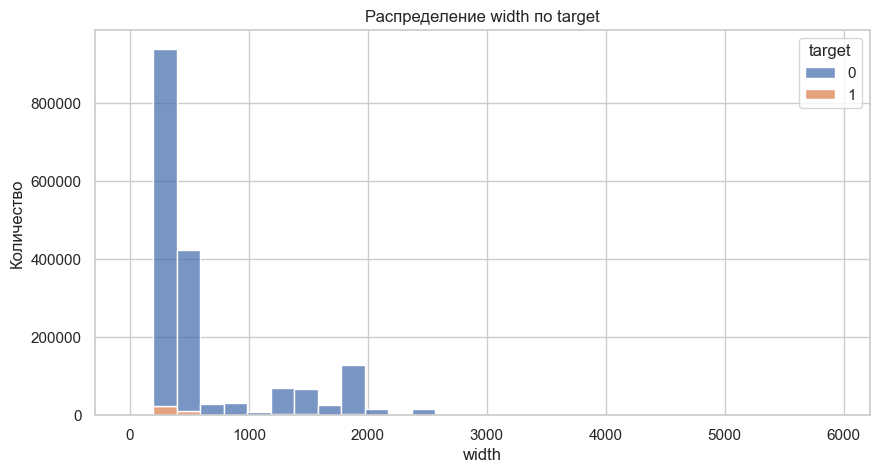

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


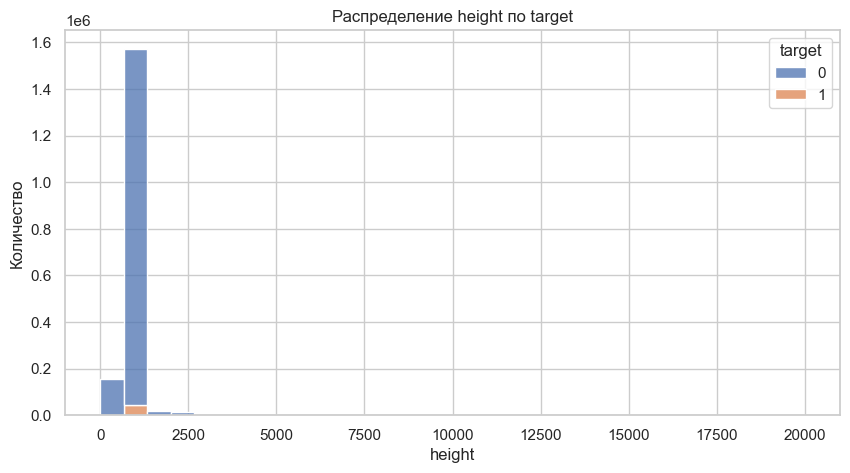

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


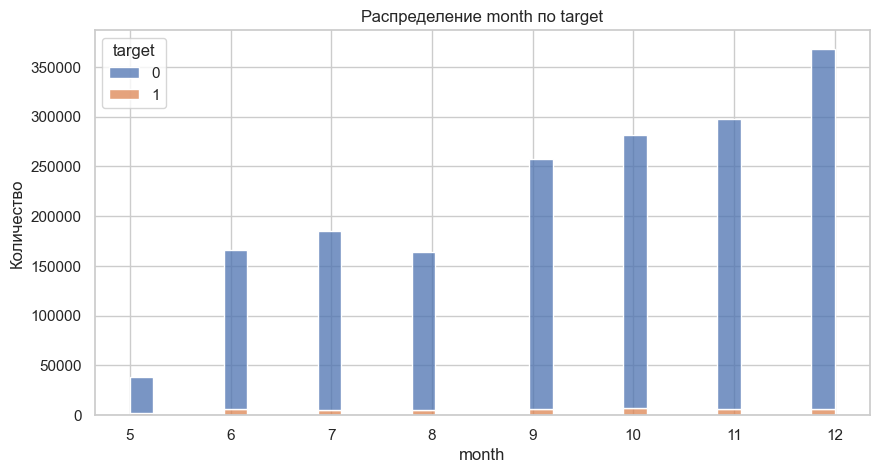

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


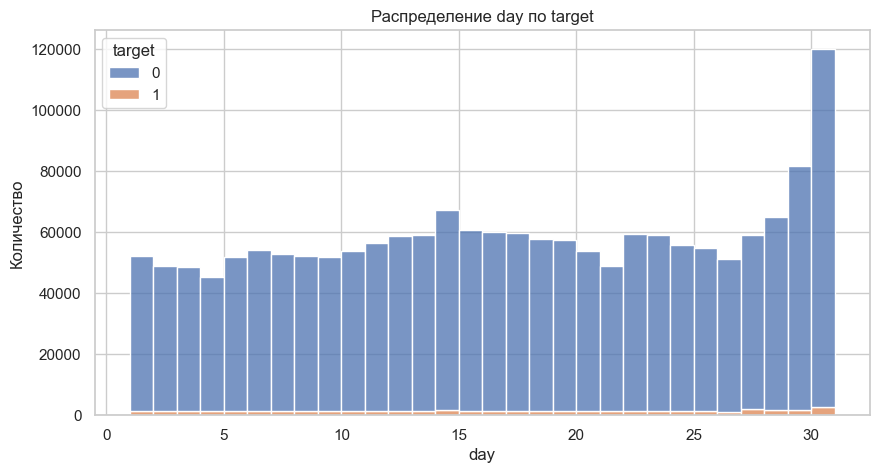

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


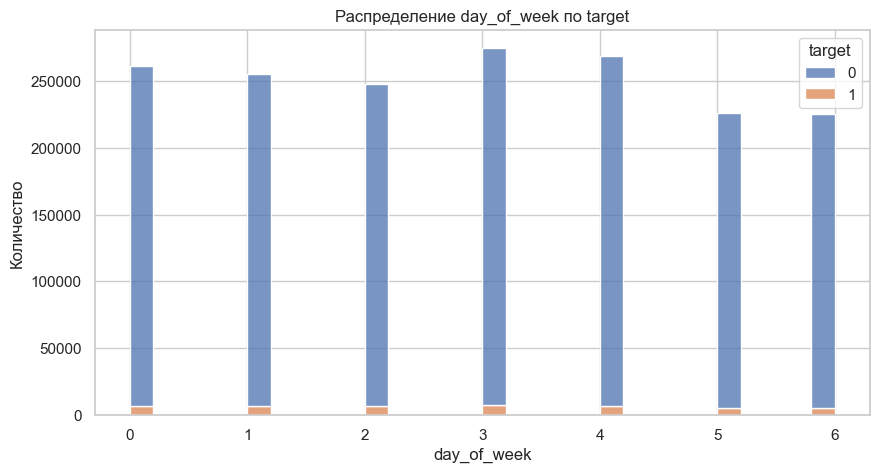

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


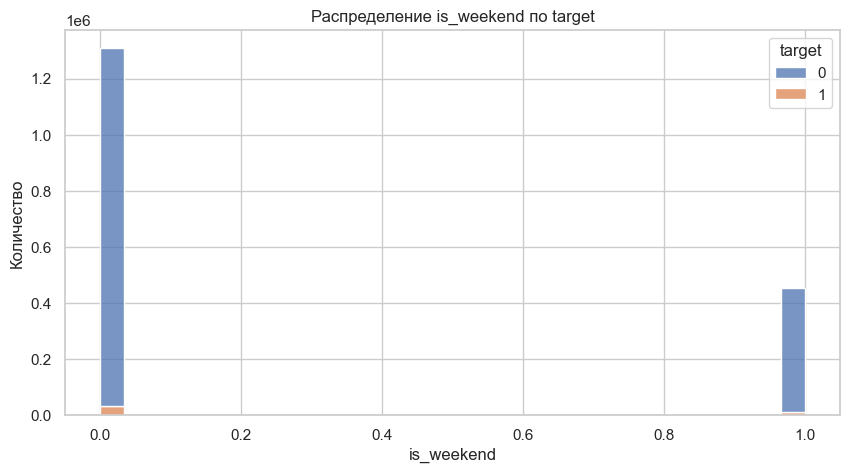

In [89]:
# 1. Визуализация распределений
# Числовые признаки
numeric_cols = ['width', 'height', 'month', 'day', 'day_of_week', 'is_weekend']
categorical_cols = [
    'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
    'device_category', 'device_os', 'device_brand', 'device_model', 'device_browser',
    'geo_country', 'geo_city', 'time_period'
]

# Гистограммы для числовых признаков
for col in numeric_cols:
    plt.figure(figsize=(10, 5))
    sns.histplot(data=df_filtered, x=col, hue='target', multiple='stack', bins=30)
    plt.title(f'Распределение {col} по target')
    plt.xlabel(col)
    plt.ylabel('Количество')
    plt.show()

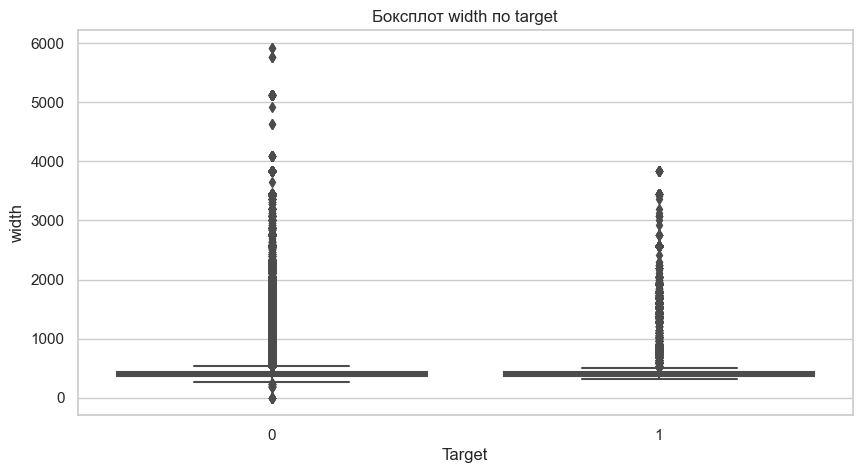

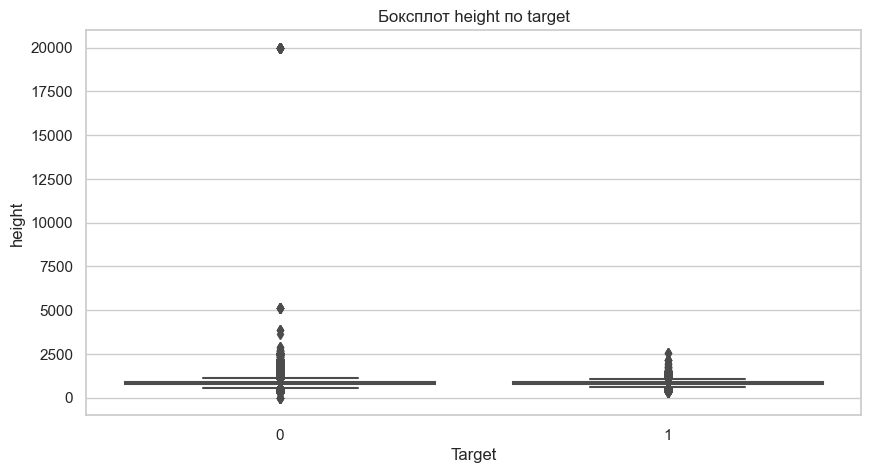

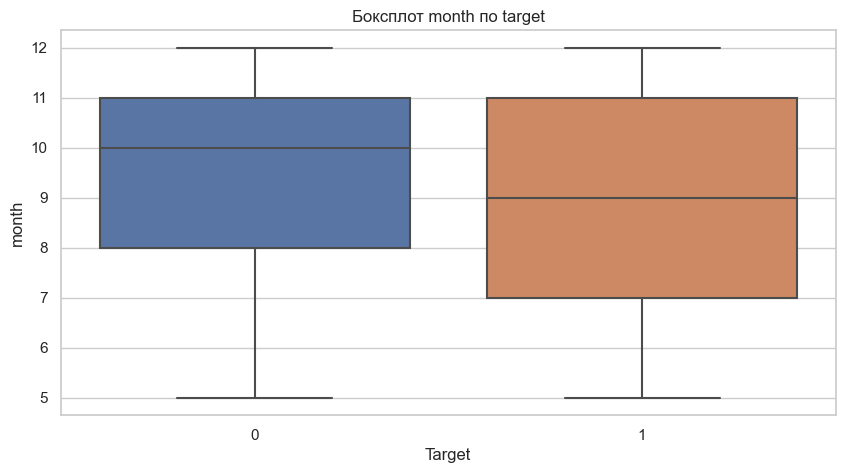

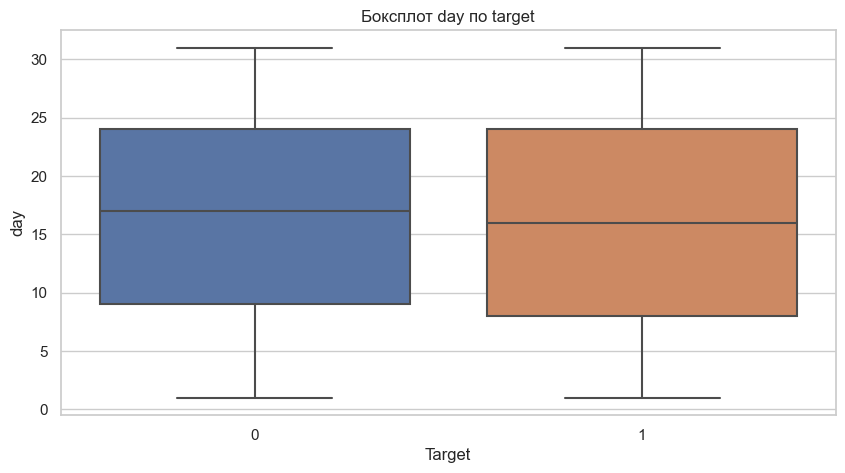

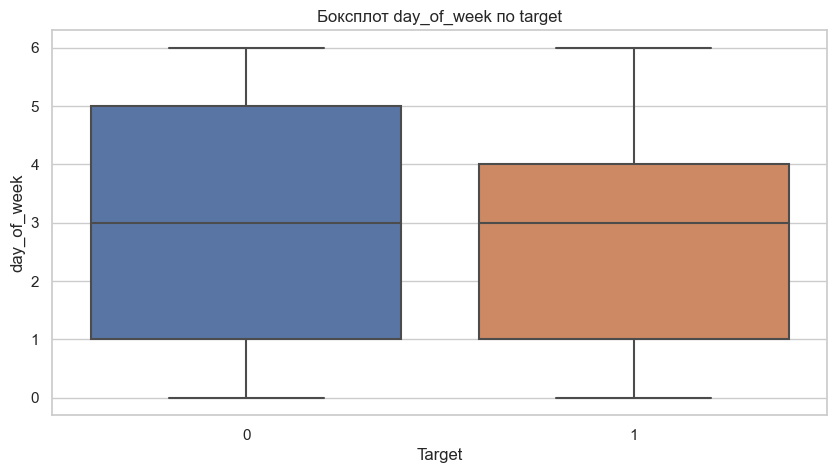

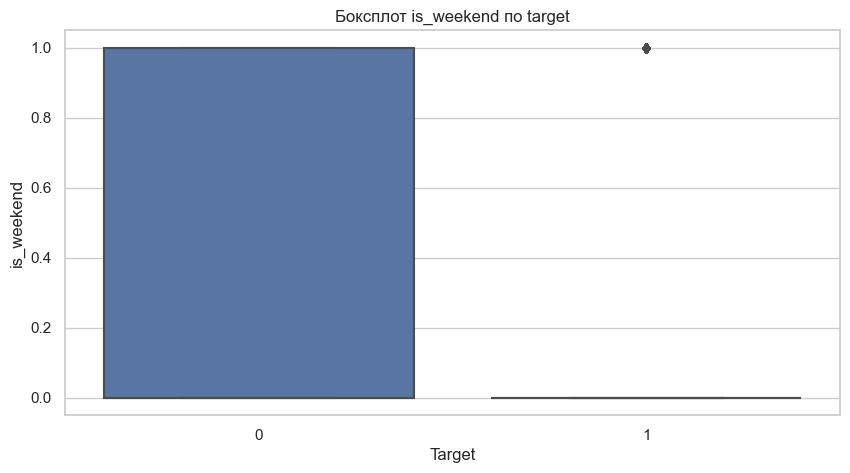

In [90]:
# Боксплоты для числовых признаков
for col in numeric_cols:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_filtered, x='target', y=col)
    plt.title(f'Боксплот {col} по target')
    plt.xlabel('Target')
    plt.ylabel(col)
    plt.show()

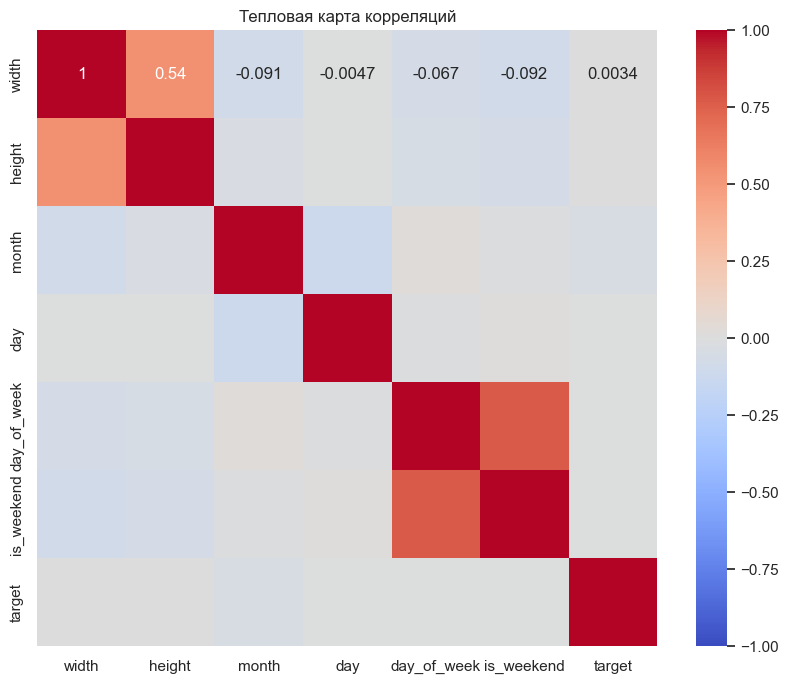

Основные корреляции с target:
target         1.000000
height         0.004947
width          0.003396
is_weekend    -0.003642
day_of_week   -0.004679
day           -0.006730
month         -0.040342
Name: target, dtype: float64


In [91]:
# 3. Корреляции
# Выбираем числовые признаки и target
corr_cols = numeric_cols + ['target']
corr_matrix = df_filtered[corr_cols].corr()

# Построение тепловой карты
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Тепловая карта корреляций')
plt.show()

# Выводы по корреляциям
print("Основные корреляции с target:")
target_corr = corr_matrix['target'].sort_values(ascending=False)
print(target_corr)

## Подготовка датасета к обучению

In [93]:
df_filtered

,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,...,geo_city,target,time_only,time_period,day_of_week,month,day,is_weekend,width,height
0,9055434745589932991.1637753792.1637753792,2108382700.163775,2021-11-24 00:00:00+00:00,1900-01-01 14:36:32+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Zlatoust,0,14:36:32,day,2,11,24,0,360,720
1,905544597018549464.1636867290.1636867290,210838531.163687,2021-11-14 00:00:00+00:00,1900-01-01 08:21:30+00:00,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,...,Moscow,0,08:21:30,morning,6,11,14,1,385,854
2,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28 00:00:00+00:00,1900-01-01 02:42:06+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,...,Krasnoyarsk,0,02:42:06,night,1,12,28,0,360,720
3,9055447046360770272.1622255328.1622255328,2108385564.162225,2021-05-29 00:00:00+00:00,1900-01-01 05:00:00+00:00,1,kjsLglQLzykiRbcDiGcD,cpc,LTuZkdKfxRGVceoWkVyg,NOBKLgtuvqYWkXQHeYWM,puhZPIYqKXeFPaUviSjo,...,Moscow,0,05:00:00,morning,5,5,29,1,393,786
4,9055447046360770272.1622255345.1622255345,2108385564.162225,2021-05-29 00:00:00+00:00,1900-01-01 05:00:00+00:00,2,kjsLglQLzykiRbcDiGcD,cpc,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,...,Moscow,0,05:00:00,morning,5,5,29,1,393,786
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860036,9055401700113249881.1639446112.1639446112,2108375006.163945,2021-12-14 00:00:00+00:00,1900-01-01 04:41:52+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,TmThBvoCcwkCZZUWACYq,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,...,Blagoveshchensk,0,04:41:52,night,1,12,14,0,360,640
1860037,9055415581448263752.1640159305.1640159305,2108378238.164016,2021-12-22 00:00:00+00:00,1900-01-01 10:48:25+00:00,1,BHcvLfOaCWvWTykYqHVe,cpc,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,VlqBmecIOXWjCWUmQkLd,...,Moscow,0,10:48:25,morning,2,12,22,0,1920,1080
1860039,9055422955903931195.1636979515.1636979515,2108379955.163698,2021-11-15 00:00:00+00:00,1900-01-01 15:31:55+00:00,1,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,...,Moscow,0,15:31:55,day,0,11,15,0,375,667
1860040,905543020766873816.1638189404.1638189404,210838164.163819,2021-11-29 00:00:00+00:00,1900-01-01 15:36:44+00:00,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,...,Chelyabinsk,0,15:36:44,day,0,11,29,0,393,851


In [94]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1759949 entries, 0 to 1860041
Data columns (total 26 columns):
 #   Column           Dtype              
---  ------           -----              
 0   session_id       object             
 1   client_id        object             
 2   visit_date       datetime64[ns, UTC]
 3   visit_time       datetime64[ns, UTC]
 4   visit_number     int64              
 5   utm_source       object             
 6   utm_medium       object             
 7   utm_campaign     object             
 8   utm_adcontent    object             
 9   utm_keyword      object             
 10  device_category  object             
 11  device_os        object             
 12  device_brand     object             
 13  device_model     object             
 14  device_browser   object             
 15  geo_country      object             
 16  geo_city         object             
 17  target           int64              
 18  time_only        object             
 19  time_

In [95]:
df_filtered['target'].value_counts()

target
0    1714992
1      44957
Name: count, dtype: int64

In [96]:
df_filtered['utm_keyword'].value_counts().head(20)

utm_keyword
puhZPIYqKXeFPaUviSjo    1491752
aXQzDWsJuGXeBXexNHjc      23967
pHqgLcdBQPSLcrTpLkdr      13590
ITfrGJNwVsHBGJMAKoct      13109
hAmNSZmQkKQKAjZEGlgb      11158
UKNBOHebRIIsQRsjNKay      10818
IGUCNvHlhfHpROGclCit       7568
RkpOyeEPgcMBSDuHLQcj       6978
JajANoFxoqXfKRNBUhzx       6659
BmOOOIoWGHEfxEfoUezs       6601
ZNhSIPchlbnKwZWcsKzz       5620
pucKZkLDtpMDBTobJAJG       5391
YQXPpoLsxnykCWKhGEmI       4785
RrhnkuoaqckNtJpAZDzH       4700
DBHgBJHOdbPwsRDUbEgX       4470
XEayFbemrPYbxFeNbxif       3678
tVtbIKrPSOvrXLCznVVe       3644
MWLEpQPyjGkjHseVyeyQ       3052
fzbotReoFzSuckjwcpCs       2965
COtBsnAzfZyRVtvDlhnW       2785
Name: count, dtype: int64

In [97]:
top_keywords = df_filtered['utm_keyword'].value_counts().head(20).index
df_filtered['utm_keyword'] = df_filtered['utm_keyword'].apply(lambda x: x if x in top_keywords else 'other')
df_filtered['utm_keyword'].value_counts().head(20)

utm_keyword
puhZPIYqKXeFPaUviSjo    1491752
other                    126659
aXQzDWsJuGXeBXexNHjc      23967
pHqgLcdBQPSLcrTpLkdr      13590
ITfrGJNwVsHBGJMAKoct      13109
hAmNSZmQkKQKAjZEGlgb      11158
UKNBOHebRIIsQRsjNKay      10818
IGUCNvHlhfHpROGclCit       7568
RkpOyeEPgcMBSDuHLQcj       6978
JajANoFxoqXfKRNBUhzx       6659
BmOOOIoWGHEfxEfoUezs       6601
ZNhSIPchlbnKwZWcsKzz       5620
pucKZkLDtpMDBTobJAJG       5391
YQXPpoLsxnykCWKhGEmI       4785
RrhnkuoaqckNtJpAZDzH       4700
DBHgBJHOdbPwsRDUbEgX       4470
XEayFbemrPYbxFeNbxif       3678
tVtbIKrPSOvrXLCznVVe       3644
MWLEpQPyjGkjHseVyeyQ       3052
fzbotReoFzSuckjwcpCs       2965
Name: count, dtype: int64

In [98]:
top_utm_source = df_filtered['utm_source'].value_counts().head(20).index
df_filtered['utm_source'] = df_filtered['utm_source'].apply(lambda x: x if x in top_utm_source else 'other')
df_filtered['utm_source'].value_counts().head(20)

utm_source
ZpYIoDJMcFzVoPFsHGJL    552652
kjsLglQLzykiRbcDiGcD    261793
fDLlAcSmythWSCVMvqvL    251259
MvfHsxITijuriZxsqZqt    185089
BHcvLfOaCWvWTykYqHVe    114821
bByPQxmDaMXgpHeypKSM     92533
QxAxdyPLuQMEcrdZWdWb     51032
other                    47222
jaSOmLICuBzCFqHfBdRg     28981
RmEBuqrriAfAVsLQQmhk     28050
aXQzDWsJuGXeBXexNHjc     27132
vFcAhRxLfOWKhvxjELkx     24135
PlbkrSYoHuZBWfYjYnfw     20792
hTjLvqNxGggkGnxSCaTm     14598
gDBGzjFKYabGgSPZvrDH     13565
fgymSoTvjKPEgaIJqsiH      9625
geDcueAOghDzHkGMmdOq      8680
ISrKoXQCxqqYvAZICvjs      8523
nSReTmyFtbSjlPrTKoaX      7253
SzZERoLMmrEUEhDaYcyN      6828
Name: count, dtype: int64

In [99]:
top_adcontent = df_filtered['utm_adcontent'].value_counts().head(20).index
df_filtered['utm_adcontent'] = df_filtered['utm_adcontent'].apply(lambda x: x if x in top_adcontent else 'other')
df_filtered['utm_adcontent'].value_counts().head(20)

utm_adcontent
JNHcPlZPxEMWDnRiyoBf    1248709
vCIpmpaGBnIQhyYNkXqp     176256
xhoenQgDQsgfEPYNPwKO     111967
PkybGvWbaqORmxjNunqZ      60315
other                     34961
LLfCasrxQzJIyuldcuWy      23948
TuyPWsGQruPMpKvRxeBF      18189
UxrnyMlRBSOhOjytXnMG      13583
dUuXlWzvmhDSyclWRhNP      10280
yYdBRbPmBMUZHXwqGxNx       9700
WYLajZgbUhGimwBKDZUH       8610
SOkCdPxfUcZUzzOdgGES       7127
AdeErYgVTbRcAWtHrMHq       6391
nNqUcgFgcqQbTVSvgaHr       6190
aYAcKhelKzYpXrRYknSP       5090
XSkXBCPfnJjvxbfeewtd       4381
XKsYZiUFcdkUXQpoLKyS       4112
FkiRXDLOWtzVfvhEkhNo       2838
xnyHaukLtAvgViiZSyBC       2582
SAVVWaMghGnnvPOqMOIt       2500
Name: count, dtype: int64

In [100]:
top_model = df_filtered['device_model'].value_counts().head(20).index
df_filtered['device_model'] = df_filtered['device_model'].apply(lambda x: x if x in top_model else 'other')
df_filtered['device_model'].value_counts().head(20)

device_model
other                   1746115
AuMdmADEIoPXiWpTsBEj       9353
cwMJxNXiWUgMUxGiCTPs        640
tWBQlsvNfHxRUjaPAfhd        626
pTgAEPipQxDXCjPrJbHo        448
FJApgTrMAGHoxCxQVKws        359
tfPZFRbtlzEssBEesRwM        325
pcvPxfVFaAmhwFmvIeYd        321
mzJXHtJPIOSHoHtgezIA        220
aCLaTVQlHcXbUnQYQvIg        220
JAIKWwxRffFOXQcfGTVi        191
zFCiMWkbbAhTflrlLWnz        169
jXFxTkHxuiBKWOvUtsIa        160
mSVMBvlHFgftJaQAZEdp        139
AshpvdJdReafUzEMmWGr        128
IiVVIXFnNMwpBtuHILvS        125
DzXtLnggNbQSyyFLKlgY        111
QIRMJBHwssjlXzlheRfO        100
wsPZygnUifLMgkSEnWLj        100
qBRdfuuhOnnqwSqNiPOv         99
Name: count, dtype: int64

In [101]:
top_brand = df_filtered['device_brand'].value_counts().head(20).index
df_filtered['device_brand'] = df_filtered['device_brand'].apply(lambda x: x if x in top_brand else 'other')
df_filtered['device_brand'].value_counts().head(20)

device_brand
Apple        520772
other        355156
Samsung      315797
Xiaomi       275756
Huawei       178278
Realme        18225
(not set)     16832
OPPO          12935
Vivo          11356
OnePlus        9218
Asus           7470
Nokia          6911
ZTE            6180
Sony           5998
Google         4831
Meizu          3611
Lenovo         3035
Blackview      2669
Tecno          2595
LG             2324
Name: count, dtype: int64

In [102]:
top_browser = df_filtered['device_browser'].value_counts().head(20).index
df_filtered['device_browser'] = df_filtered['device_browser'].apply(lambda x: x if x in top_browser else 'other')
df_filtered['device_browser'].value_counts().head(20)

device_browser
Chrome                              961188
Safari                              450391
YaBrowser                           124656
Safari (in-app)                      67497
Android Webview                      54270
Samsung Internet                     45096
Opera                                24648
Edge                                 14825
Firefox                              14776
UC Browser                             836
Android Runtime                        392
Mozilla Compatible Agent               346
other                                  269
[FBAN                                  268
Instagram 208.0.0.32.135 Android       140
Instagram 209.0.0.21.119 Android       111
MRCHROME                                74
Android Browser                         45
Opera Mini                              44
Puffin                                  41
Name: count, dtype: int64

In [103]:
top_country = df_filtered['geo_country'].value_counts().head(20).index
df_filtered['geo_country'] = df_filtered['geo_country'].apply(lambda x: x if x in top_country else 'other')
df_filtered['geo_country'].value_counts().head(20)

geo_country
Russia            1703826
United States       11453
other                9904
Ukraine              8495
Ireland              4023
Belarus              3461
Sweden               2578
Kazakhstan           2161
Germany              2000
Turkey               1881
Uzbekistan           1458
Netherlands          1360
United Kingdom       1343
(not set)            1050
Kyrgyzstan            902
Georgia               884
France                724
Cyprus                683
Armenia               626
Finland               591
Name: count, dtype: int64

In [104]:
df_filtered['geo_city'].value_counts().head(20)

geo_city
Moscow              754508
Saint Petersburg    281601
(not set)            75124
Yekaterinburg        33990
Krasnodar            30867
Kazan                28096
Samara               23657
Nizhny Novgorod      21145
Ufa                  20864
Novosibirsk          20633
Krasnoyarsk          15783
Chelyabinsk          15291
Tula                 14568
Voronezh             13317
Rostov-on-Don        13205
Irkutsk              13175
Grozny               12333
Balashikha           12115
Vladivostok          12019
Yaroslavl             9352
Name: count, dtype: int64

In [105]:
top_cities = df_filtered['geo_city'].value_counts().head(20).index
df_filtered['geo_city'] = df_filtered['geo_city'].apply(lambda x: x if x in top_cities else 'other')
df_filtered['geo_city'].value_counts().head(20)

geo_city
Moscow              754508
other               338306
Saint Petersburg    281601
(not set)            75124
Yekaterinburg        33990
Krasnodar            30867
Kazan                28096
Samara               23657
Nizhny Novgorod      21145
Ufa                  20864
Novosibirsk          20633
Krasnoyarsk          15783
Chelyabinsk          15291
Tula                 14568
Voronezh             13317
Rostov-on-Don        13205
Irkutsk              13175
Grozny               12333
Balashikha           12115
Vladivostok          12019
Name: count, dtype: int64

In [106]:
df_filtered['utm_campaign'].value_counts().head(20)

utm_campaign
LTuZkdKfxRGVceoWkVyg    611688
LEoPHuyFvzoNfnzGgfcd    318808
FTjNLDyTrXaWYgZymFkV    246254
gecBYcKZCPMcVYdSSzKP    134016
TmThBvoCcwkCZZUWACYq     26595
XHNUiSKKGTEpSAlaVMFQ     24338
okTXSMadDkjvntEHzIjp     24233
SgIUDYUKnyWHVowUOqid     22841
LwJZxKuWmvOhPsaCeRjG     17589
RoDitORHdzGfGhNCyEMy     15676
bxOTvPtyGSdUrbwoXCPO     15411
bJJuEXRheRIxXEaYIXqM     12210
YCKgTzTDywjcWyQudGch     12037
zxoiLxhuSIFrCeTLQVWZ     11634
nSReTmyFtbSjlPrTKoaX     11602
QEejXfOCtOMFLZqIPApp     10172
vRLTQQKAsFQMxbcHGPhu      9461
jvsVVQVKRfBIqBDBuCkq      7913
eimRuUrNhZLAYcwRrNXu      7730
VBmazutCflYumtDHrQYe      7467
Name: count, dtype: int64

In [107]:
top_campaign = df_filtered['utm_campaign'].value_counts().head(20).index
df_filtered['utm_campaign'] = df_filtered['utm_campaign'].apply(lambda x: x if x in top_campaign else 'other')
df_filtered['utm_campaign'].value_counts().head(20)

utm_campaign
LTuZkdKfxRGVceoWkVyg    611688
LEoPHuyFvzoNfnzGgfcd    318808
FTjNLDyTrXaWYgZymFkV    246254
other                   212274
gecBYcKZCPMcVYdSSzKP    134016
TmThBvoCcwkCZZUWACYq     26595
XHNUiSKKGTEpSAlaVMFQ     24338
okTXSMadDkjvntEHzIjp     24233
SgIUDYUKnyWHVowUOqid     22841
LwJZxKuWmvOhPsaCeRjG     17589
RoDitORHdzGfGhNCyEMy     15676
bxOTvPtyGSdUrbwoXCPO     15411
bJJuEXRheRIxXEaYIXqM     12210
YCKgTzTDywjcWyQudGch     12037
zxoiLxhuSIFrCeTLQVWZ     11634
nSReTmyFtbSjlPrTKoaX     11602
QEejXfOCtOMFLZqIPApp     10172
vRLTQQKAsFQMxbcHGPhu      9461
jvsVVQVKRfBIqBDBuCkq      7913
eimRuUrNhZLAYcwRrNXu      7730
Name: count, dtype: int64

In [108]:
# 1. Проверка текущего распределения time_only
print("Текущие топ-10 значений time_only:")
print(df_filtered['time_only'].value_counts().head(10))

# 2. Преобразование time_only в hour
# Вариант 1: Если time_only — строка (HH:MM:SS)
#df_filtered['hour'] = df_filtered['time_only'].str.split(':').str[0].astype(int)

# Вариант 2: Если time_only нужно сначала преобразовать в datetime
df_filtered['hour'] = pd.to_datetime(df_filtered['time_only'], format='%H:%M:%S').dt.hour.astype(int)

# 3. Проверка нового столбца hour
print("\nТоп-10 значений hour после преобразования:")
print(df_filtered['hour'].value_counts().head(10))

#4. Удаление столбца time_only, если он больше не нужен
df_filtered = df_filtered.drop(columns=['time_only'])

Текущие топ-10 значений time_only:
time_only
14:00:00    55554
12:00:00    55539
13:00:00    55505
16:00:00    54874
11:00:00    54455
10:00:00    54200
18:00:00    53490
15:00:00    53245
19:00:00    52935
20:00:00    52895
Name: count, dtype: int64

Топ-10 значений hour после преобразования:
hour
14    98430
18    97583
16    96913
15    96771
13    96339
12    95895
11    95277
19    95005
20    94864
17    94798
Name: count, dtype: int64


In [109]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1759949 entries, 0 to 1860041
Data columns (total 26 columns):
 #   Column           Dtype              
---  ------           -----              
 0   session_id       object             
 1   client_id        object             
 2   visit_date       datetime64[ns, UTC]
 3   visit_time       datetime64[ns, UTC]
 4   visit_number     int64              
 5   utm_source       object             
 6   utm_medium       object             
 7   utm_campaign     object             
 8   utm_adcontent    object             
 9   utm_keyword      object             
 10  device_category  object             
 11  device_os        object             
 12  device_brand     object             
 13  device_model     object             
 14  device_browser   object             
 15  geo_country      object             
 16  geo_city         object             
 17  target           int64              
 18  time_period      object             
 19  day_o

In [110]:
categorical_columns = [
    'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
    'device_os','device_brand', 'device_model', 'device_browser',
    'time_period', 'geo_country', 'geo_city'
]
df_filtered[categorical_columns] = df_filtered[categorical_columns].astype('category')
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1759949 entries, 0 to 1860041
Data columns (total 26 columns):
 #   Column           Dtype              
---  ------           -----              
 0   session_id       object             
 1   client_id        object             
 2   visit_date       datetime64[ns, UTC]
 3   visit_time       datetime64[ns, UTC]
 4   visit_number     int64              
 5   utm_source       category           
 6   utm_medium       category           
 7   utm_campaign     category           
 8   utm_adcontent    category           
 9   utm_keyword      category           
 10  device_category  object             
 11  device_os        category           
 12  device_brand     category           
 13  device_model     category           
 14  device_browser   category           
 15  geo_country      category           
 16  geo_city         category           
 17  target           int64              
 18  time_period      category           
 19  day_o

In [111]:
df_filtered[categorical_columns].nunique()

utm_source        21
utm_medium        54
utm_campaign      21
utm_adcontent     21
utm_keyword       21
device_os         14
device_brand      20
device_model      20
device_browser    21
time_period        4
geo_country       21
geo_city          21
dtype: int64

In [112]:
df_filtered['device_category'] = df_filtered['device_category'].map({'mobile': 0, 'desktop': 1, 'tablet': 2})
df_filtered['device_category'].value_counts()

device_category
0    1402479
1     339980
2      17490
Name: count, dtype: int64

# Обучение модели

In [114]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1759949 entries, 0 to 1860041
Data columns (total 26 columns):
 #   Column           Dtype              
---  ------           -----              
 0   session_id       object             
 1   client_id        object             
 2   visit_date       datetime64[ns, UTC]
 3   visit_time       datetime64[ns, UTC]
 4   visit_number     int64              
 5   utm_source       category           
 6   utm_medium       category           
 7   utm_campaign     category           
 8   utm_adcontent    category           
 9   utm_keyword      category           
 10  device_category  int64              
 11  device_os        category           
 12  device_brand     category           
 13  device_model     category           
 14  device_browser   category           
 15  geo_country      category           
 16  geo_city         category           
 17  target           int64              
 18  time_period      category           
 19  day_o

In [115]:
df_filtered = df_filtered.drop(columns=['session_id'])

In [116]:
df_filtered = df_filtered.drop(columns=['client_id'])

In [117]:
df_filtered = df_filtered.drop(columns=['visit_date'])

In [118]:
df_filtered = df_filtered.drop(columns=['visit_time'])

In [119]:
df_filtered = df_filtered.drop(columns=['visit_number'])

In [120]:
df_filtered

,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_browser,...,geo_city,target,time_period,day_of_week,month,day,is_weekend,width,height,hour
0,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,0,Android,Huawei,other,Chrome,...,other,0,day,2,11,24,0,360,720,14
1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,0,Android,Samsung,other,Samsung Internet,...,Moscow,0,morning,6,11,14,1,385,854,8
2,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,0,Android,Huawei,other,Chrome,...,Krasnoyarsk,0,night,1,12,28,0,360,720,2
3,kjsLglQLzykiRbcDiGcD,cpc,LTuZkdKfxRGVceoWkVyg,other,puhZPIYqKXeFPaUviSjo,0,other,Xiaomi,other,Chrome,...,Moscow,0,morning,5,5,29,1,393,786,5
4,kjsLglQLzykiRbcDiGcD,cpc,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,other,Xiaomi,other,Chrome,...,Moscow,0,morning,5,5,29,1,393,786,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1860036,ZpYIoDJMcFzVoPFsHGJL,banner,TmThBvoCcwkCZZUWACYq,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,Android,ZTE,other,Chrome,...,other,0,night,1,12,14,0,360,640,4
1860037,BHcvLfOaCWvWTykYqHVe,cpc,LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,other,1,Windows,other,other,Chrome,...,Moscow,0,morning,2,12,22,0,1920,1080,10
1860039,fDLlAcSmythWSCVMvqvL,(none),LTuZkdKfxRGVceoWkVyg,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,iOS,Apple,other,Safari,...,Moscow,0,day,0,11,15,0,375,667,15
1860040,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,JNHcPlZPxEMWDnRiyoBf,puhZPIYqKXeFPaUviSjo,0,Android,Xiaomi,other,Chrome,...,Chelyabinsk,0,day,0,11,29,0,393,851,15


In [121]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1759949 entries, 0 to 1860041
Data columns (total 21 columns):
 #   Column           Dtype   
---  ------           -----   
 0   utm_source       category
 1   utm_medium       category
 2   utm_campaign     category
 3   utm_adcontent    category
 4   utm_keyword      category
 5   device_category  int64   
 6   device_os        category
 7   device_brand     category
 8   device_model     category
 9   device_browser   category
 10  geo_country      category
 11  geo_city         category
 12  target           int64   
 13  time_period      category
 14  day_of_week      int32   
 15  month            int32   
 16  day              int32   
 17  is_weekend       int64   
 18  width            int64   
 19  height           int64   
 20  hour             int64   
dtypes: category(12), int32(3), int64(6)
memory usage: 134.3 MB


In [122]:
# 2. Список числовых столбцов
numeric_cols = ['device_category', 'target', 'is_weekend', 'width', 'height', 
                'hour', 'day_of_week', 'month', 'day']

# 3. Downcast числовых столбцов
for col in numeric_cols:
    df_filtered[col] = pd.to_numeric(df_filtered[col], downcast='integer')

# 4. Вывод информации после downcast
print("\nИнформация о df_filtered после downcast:")
df_filtered.info()


Информация о df_filtered после downcast:
<class 'pandas.core.frame.DataFrame'>
Index: 1759949 entries, 0 to 1860041
Data columns (total 21 columns):
 #   Column           Dtype   
---  ------           -----   
 0   utm_source       category
 1   utm_medium       category
 2   utm_campaign     category
 3   utm_adcontent    category
 4   utm_keyword      category
 5   device_category  int8    
 6   device_os        category
 7   device_brand     category
 8   device_model     category
 9   device_browser   category
 10  geo_country      category
 11  geo_city         category
 12  target           int8    
 13  time_period      category
 14  day_of_week      int8    
 15  month            int8    
 16  day              int8    
 17  is_weekend       int8    
 18  width            int16   
 19  height           int16   
 20  hour             int8    
dtypes: category(12), int16(2), int8(7)
memory usage: 52.0 MB


In [123]:
# 📌 Разделяем на train/test
X = df_filtered.drop(columns=['target'])  
y = df_filtered['target']  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [124]:
# 📌 Определяем категориальные и числовые признаки
categorical_cols = X_train.select_dtypes(include=['category']).columns
numeric_cols = X_train.select_dtypes(include=['int8', 'int16', 'int32', 'int64']).columns

In [125]:
ohe = OneHotEncoder(sparse_output=False, dtype="int8", handle_unknown="ignore")
X_train_cat = ohe.fit_transform(X_train[categorical_cols])
X_test_cat = ohe.transform(X_test[categorical_cols])

In [126]:
# 📌 Масштабируем числовые признаки
scaler = MinMaxScaler()
X_train_num = scaler.fit_transform(X_train[numeric_cols])
X_test_num = scaler.transform(X_test[numeric_cols])

In [127]:
# 📌 Собираем обработанные данные в датафреймы
X_train_final = pd.DataFrame(X_train_cat, columns=ohe.get_feature_names_out(), index=X_train.index)
X_train_final[numeric_cols] = X_train_num

X_test_final = pd.DataFrame(X_test_cat, columns=ohe.get_feature_names_out(), index=X_test.index)
X_test_final[numeric_cols] = X_test_num

In [128]:
X_train_final

,utm_source_BHcvLfOaCWvWTykYqHVe,utm_source_ISrKoXQCxqqYvAZICvjs,utm_source_MvfHsxITijuriZxsqZqt,utm_source_PlbkrSYoHuZBWfYjYnfw,utm_source_QxAxdyPLuQMEcrdZWdWb,utm_source_RmEBuqrriAfAVsLQQmhk,utm_source_SzZERoLMmrEUEhDaYcyN,utm_source_ZpYIoDJMcFzVoPFsHGJL,utm_source_aXQzDWsJuGXeBXexNHjc,utm_source_bByPQxmDaMXgpHeypKSM,...,time_period_morning,time_period_night,device_category,day_of_week,month,day,is_weekend,width,height,hour
570725,0,0,0,0,0,0,0,0,0,0,...,0,0,0.5,0.166667,0.142857,0.933333,0.0,0.324105,0.05400,0.695652
162426,0,0,0,0,0,0,0,1,0,0,...,1,0,0.0,0.000000,0.714286,0.333333,0.0,0.060770,0.03900,0.434783
1009825,0,0,0,0,0,0,0,0,0,0,...,0,0,0.0,1.000000,0.857143,0.666667,1.0,0.066340,0.04255,0.608696
1195836,0,0,0,0,0,0,0,1,0,0,...,0,1,0.0,0.500000,0.857143,0.333333,0.0,0.060770,0.04000,0.000000
240077,0,0,0,0,0,0,0,1,0,0,...,1,0,0.0,0.333333,1.000000,0.000000,0.0,0.063302,0.04060,0.347826
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
538346,0,0,0,0,0,0,0,0,0,0,...,1,0,0.5,0.666667,1.000000,1.000000,0.0,0.324105,0.05400,0.260870
748047,0,0,0,0,0,0,0,0,0,0,...,1,0,1.0,0.166667,0.142857,0.933333,0.0,0.129642,0.05120,0.391304
589217,0,0,0,0,1,0,0,0,0,0,...,0,0,0.0,1.000000,0.714286,0.766667,1.0,0.063302,0.03335,0.521739
1292531,0,0,0,0,0,0,0,0,0,0,...,0,1,0.0,0.666667,0.428571,0.166667,0.0,0.069885,0.04480,1.000000


In [129]:
X_test_final

,utm_source_BHcvLfOaCWvWTykYqHVe,utm_source_ISrKoXQCxqqYvAZICvjs,utm_source_MvfHsxITijuriZxsqZqt,utm_source_PlbkrSYoHuZBWfYjYnfw,utm_source_QxAxdyPLuQMEcrdZWdWb,utm_source_RmEBuqrriAfAVsLQQmhk,utm_source_SzZERoLMmrEUEhDaYcyN,utm_source_ZpYIoDJMcFzVoPFsHGJL,utm_source_aXQzDWsJuGXeBXexNHjc,utm_source_bByPQxmDaMXgpHeypKSM,...,time_period_morning,time_period_night,device_category,day_of_week,month,day,is_weekend,width,height,hour
1077823,0,0,0,0,0,0,0,1,0,0,...,0,0,0.0,0.333333,0.714286,0.400000,0.0,0.066340,0.04255,0.739130
121929,0,0,0,0,0,0,0,0,0,0,...,0,0,0.5,0.833333,1.000000,0.800000,1.0,0.230587,0.03840,0.652174
1664000,0,0,0,0,0,0,0,1,0,0,...,1,0,0.0,0.833333,0.714286,0.733333,1.0,0.060770,0.04000,0.260870
325595,0,0,0,0,0,0,0,0,0,0,...,1,0,0.5,0.000000,0.285714,0.133333,0.0,0.324105,0.05400,0.478261
1726912,1,0,0,0,0,0,0,0,0,0,...,1,0,0.0,0.500000,0.714286,0.900000,0.0,0.066340,0.04255,0.434783
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1722401,0,0,0,0,0,0,0,0,0,1,...,0,0,0.0,1.000000,0.285714,0.800000,1.0,0.064990,0.04270,0.608696
491373,0,0,1,0,0,0,0,0,0,0,...,0,1,0.0,0.500000,0.428571,0.600000,0.0,0.054018,0.02670,1.000000
645283,0,0,0,0,1,0,0,0,0,0,...,0,0,0.0,0.666667,1.000000,1.000000,0.0,0.063302,0.03335,0.782609
1290478,0,0,0,0,0,0,0,0,0,0,...,0,0,0.0,1.000000,0.285714,0.333333,1.0,0.060770,0.03200,0.869565


In [130]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

target
0    0.974455
1    0.025545
Name: proportion, dtype: float64
target
0    0.974457
1    0.025543
Name: proportion, dtype: float64


In [131]:
# Определяем метрику для GridSearchCV
auc_scorer = make_scorer(roc_auc_score, needs_proba=True)

In [132]:
# 📌 Обучаем модели

# 1️⃣ Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state = 42)
log_reg.fit(X_train_final, y_train)
y_pred_log = log_reg.predict(X_test_final)
y_pred_proba_log = log_reg.predict_proba(X_test_final)[:, 1]

In [133]:
# Модель Random Forest
rf = RandomForestClassifier(random_state=42)

# Сетка гиперпараметров
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced', None]
}

# GridSearchCV
rf_grid = GridSearchCV(
    estimator=rf,
    param_grid=rf_param_grid,
    scoring=auc_scorer,
    cv=3,  # 3-кратная кросс-валидация
    n_jobs=-1,  # Использовать все ядра процессора
    verbose=1
)

# Обучение
rf_grid.fit(X_train_final, y_train)
best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test_final)
y_pred_proba_rf = best_rf.predict_proba(X_test_final)[:, 1]

# Вывод лучших параметров и результата
print("Лучшие параметры Random Forest:", rf_grid.best_params_)

Fitting 3 folds for each of 48 candidates, totalling 144 fits


/opt/anaconda3/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:700: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Лучшие параметры Random Forest: {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}


In [134]:
cat_features = X_train.select_dtypes(include=['category']).columns.tolist()
# Модель LightGBM
lgbm = LGBMClassifier(random_state=42, verbose=-1)

# Сетка гиперпараметров
lgbm_param_grid = {
    'num_leaves': [31, 50, 100],
    'max_depth': [6, 10, -1],  # -1 означает без ограничения
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200],
    'is_unbalance': [True, False]
}

# GridSearchCV
lgbm_grid = GridSearchCV(
    estimator=lgbm,
    param_grid=lgbm_param_grid,
    scoring=auc_scorer,
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Обучение
lgbm_grid.fit(X_train, y_train, categorical_feature=cat_features)
best_lgbm = lgbm_grid.best_estimator_
y_pred_lgbm = best_lgbm.predict(X_test)
y_pred_proba_lgbm = best_lgbm.predict_proba(X_test)[:, 1]

# Вывод лучших параметров и результата
print("Лучшие параметры LightGBM:", lgbm_grid.best_params_)

Fitting 3 folds for each of 108 candidates, totalling 324 fits


/opt/anaconda3/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:700: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Лучшие параметры LightGBM: {'is_unbalance': False, 'learning_rate': 0.05, 'max_depth': -1, 'n_estimators': 100, 'num_leaves': 100}


In [135]:
# Модель
cat = CatBoostClassifier(verbose=0, random_state=42)

# Сетка гиперпараметров
cat_param_grid = {
    'iterations': [100, 200],
    'depth': [4, 6, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'l2_leaf_reg': [1, 3, 5],
    'auto_class_weights': ['Balanced', None]
}

# GridSearchCV
cat_grid = GridSearchCV(
    estimator=cat,
    param_grid=cat_param_grid,
    scoring=auc_scorer,
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Обучение на данных с категориальными признаками
cat_grid.fit(X_train, y_train, cat_features=cat_features)
best_cat = cat_grid.best_estimator_
y_pred_cat = best_cat.predict(X_test)
y_pred_proba_cat = best_cat.predict_proba(X_test)[:, 1]

# Лучшие параметры и результат
print("Лучшие параметры CatBoost:", cat_grid.best_params_)

Fitting 3 folds for each of 108 candidates, totalling 324 fits


/opt/anaconda3/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:700: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/model_selection/_validation.py:378: FitFailedWarning: 
162 fits failed out of a total of 324.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
162 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.11/site-packages/sklearn/model_selection/_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/opt/anaconda3/lib/python3.11/site-packages/c

Лучшие параметры CatBoost: {'auto_class_weights': 'Balanced', 'depth': 6, 'iterations': 200, 'l2_leaf_reg': 3, 'learning_rate': 0.1}


In [136]:
# Вывод метрик
print(f"Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_log):.4f}")
print(f"Logistic Regression AUC: {roc_auc_score(y_test, y_pred_proba_log):.4f}")
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Random Forest Best Params: {rf_grid.best_params_}")
print(f"Random Forest Best AUC (CV): {rf_grid.best_score_:.4f}")
print(f"Random Forest AUC (Test): {roc_auc_score(y_test, y_pred_proba_rf):.4f}")
print(f"LightGBM Accuracy: {accuracy_score(y_test, y_pred_lgbm):.4f}")
print(f"LightGBM Best Params: {lgbm_grid.best_params_}")
print(f"LightGBM Best AUC (CV): {lgbm_grid.best_score_:.4f}")
print(f"LightGBM AUC (Test): {roc_auc_score(y_test, y_pred_proba_lgbm):.4f}")
print(f"CatBoost Accuracy: {accuracy_score(y_test, y_pred_cat):.4f}")
print(f"CatBoost Best Params: {cat_grid.best_params_}")
print(f"CatBoost Best AUC (CV): {cat_grid.best_score_:.4f}")
print(f"CatBoost AUC (Test): {roc_auc_score(y_test, y_pred_proba_cat):.4f}")

Logistic Regression Accuracy: 0.9745
Logistic Regression AUC: 0.6768
Random Forest Accuracy: 0.9745
Random Forest Best Params: {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Random Forest Best AUC (CV): 0.6958
Random Forest AUC (Test): 0.6992
LightGBM Accuracy: 0.9745
LightGBM Best Params: {'is_unbalance': False, 'learning_rate': 0.05, 'max_depth': -1, 'n_estimators': 100, 'num_leaves': 100}
LightGBM Best AUC (CV): 0.7009
LightGBM AUC (Test): 0.7026
CatBoost Accuracy: 0.5909
CatBoost Best Params: {'auto_class_weights': 'Balanced', 'depth': 6, 'iterations': 200, 'l2_leaf_reg': 3, 'learning_rate': 0.1}
CatBoost Best AUC (CV): 0.6944
CatBoost AUC (Test): 0.6958


In [137]:
print("Logistic Regression:\n", classification_report(y_test, y_pred_log))
print("Random Forest:\n", classification_report(y_test, y_pred_rf))
print("LightGBM:\n", classification_report(y_test, y_pred_lgbm))
print("CatBoost:\n", classification_report(y_test, y_pred_cat))

/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/anaconda3/lib/python3.11/site-packages/sklearn/

Logistic Regression:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99    342999
           1       0.00      0.00      0.00      8991

    accuracy                           0.97    351990
   macro avg       0.49      0.50      0.49    351990
weighted avg       0.95      0.97      0.96    351990

Random Forest:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99    342999
           1       0.00      0.00      0.00      8991

    accuracy                           0.97    351990
   macro avg       0.49      0.50      0.49    351990
weighted avg       0.95      0.97      0.96    351990



/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


LightGBM:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99    342999
           1       0.71      0.00      0.01      8991

    accuracy                           0.97    351990
   macro avg       0.84      0.50      0.50    351990
weighted avg       0.97      0.97      0.96    351990

CatBoost:
               precision    recall  f1-score   support

           0       0.99      0.59      0.74    342999
           1       0.04      0.69      0.08      8991

    accuracy                           0.59    351990
   macro avg       0.51      0.64      0.41    351990
weighted avg       0.96      0.59      0.72    351990



In [138]:
# Собираем метрики для каждой модели
models = {
    'Logistic Regression': (y_pred_log, y_pred_proba_log),
    'Random Forest': (y_pred_rf, y_pred_proba_rf),
    'LightGBM': (y_pred_lgbm, y_pred_proba_lgbm),
    'CatBoost': (y_pred_cat, y_pred_proba_cat)
}

# Создаем пустой список для хранения метрик
metrics_list = []

# Вычисляем метрики для каждой модели
for model_name, (y_pred, y_pred_proba) in models.items():
    # Accuracy и AUC
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_proba)
    
    # Precision, Recall, F1 для класса 1
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')
    
    # Добавляем метрики в список
    metrics_list.append({
        'Model': model_name,
        'Accuracy': acc,
        'ROC-AUC': auc,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

# Создаем DataFrame
metrics_df = pd.DataFrame(metrics_list)

# Выводим DataFrame
print("\nСравнение метрик моделей:")
print(metrics_df)


/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))



Сравнение метрик моделей:
                 Model  Accuracy   ROC-AUC  Precision    Recall  F1-Score
0  Logistic Regression  0.974457  0.676755   0.000000  0.000000  0.000000
1        Random Forest  0.974457  0.699189   0.000000  0.000000  0.000000
2             LightGBM  0.974505  0.702649   0.707317  0.003225  0.006422
3             CatBoost  0.590932  0.695842   0.041982  0.688133  0.079137


In [139]:
importances = pd.Series(best_rf.feature_importances_, index=X_train_final.columns)
print(importances.sort_values(ascending=False).head(10))

day                                   0.097390
hour                                  0.081678
height                                0.081512
month                                 0.064169
width                                 0.062794
day_of_week                           0.056216
utm_medium_referral                   0.021709
utm_campaign_LTuZkdKfxRGVceoWkVyg     0.018291
utm_source_bByPQxmDaMXgpHeypKSM       0.016609
utm_adcontent_JNHcPlZPxEMWDnRiyoBf    0.015698
dtype: float64


In [141]:
# 1. Установка отображения всех столбцов
pd.set_option('display.max_columns', None)

# 2. Предсказания модели LightGBM на тестовом наборе
y_pred_lgbm = best_lgbm.predict(X_test)
y_pred_proba_lgbm = best_lgbm.predict_proba(X_test)[:, 1]

# 3. Извлечение строк с положительными предсказаниями (y_pred_lgbm == 1)
positive_pred_indices = X_test[y_pred_lgbm == 1].index
X_test_positive_pred = X_test.loc[positive_pred_indices]
y_test_positive_pred = y_test.loc[positive_pred_indices]
y_pred_proba_positive_pred = y_pred_proba_lgbm[y_pred_lgbm == 1]

# 4. Создание DataFrame с положительными предсказаниями
positive_pred_df = X_test_positive_pred.copy()
positive_pred_df['true_target'] = y_test_positive_pred
positive_pred_df['predicted_target'] = 1
positive_pred_df['predicted_proba'] = y_pred_proba_positive_pred

# 5. Вывод строк с положительными предсказаниями
print("Строки с положительными предсказаниями LightGBM (target=1):")
print(positive_pred_df)
print(f"\nКоличество положительных предсказаний: {len(positive_pred_df)}")

# 6. Анализ истинно положительных (TP) и ложно положительных (FP)
tp_count = len(positive_pred_df[positive_pred_df['true_target'] == 1])
fp_count = len(positive_pred_df[positive_pred_df['true_target'] == 0])
print(f"\nИстинно положительные (TP): {tp_count}")
print(f"Ложно положительные (FP): {fp_count}")
print(f"Precision (TP / (TP + FP)): {tp_count / (tp_count + fp_count) if (tp_count + fp_count) > 0 else 0:.4f}")

# 7. Создание JSON-файлов для 5 положительных предсказаний
# Создаем папку для JSON-файлов, если она не существует
os.makedirs('positive_pred_jsons', exist_ok=True)

# Выбираем до 5 строк (или все, если их меньше)
n_samples = min(30, len(positive_pred_df))
selected_rows = positive_pred_df.iloc[:n_samples]

# Список столбцов, ожидаемых в Form (из main.py)
form_columns = [
    'utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
    'device_category', 'device_os', 'device_brand', 'device_model', 'device_browser',
    'geo_country', 'geo_city', 'month', 'day', 'hour', 'day_of_week',
    'is_weekend', 'width', 'height', 'time_period'
]

for i, row in selected_rows.iterrows():
    # Создаем словарь для JSON, включающий только нужные столбцы
    row_dict = row[form_columns].to_dict()
    
    # Преобразуем типы данных для соответствия Form в main.py
    row_dict['device_category'] = int(row_dict['device_category'])
    #row_dict['year'] = int(row_dict['year'])
    row_dict['month'] = int(row_dict['month'])
    row_dict['day'] = int(row_dict['day'])
    row_dict['hour'] = int(row_dict['hour'])
    row_dict['day_of_week'] = int(row_dict['day_of_week'])
    row_dict['is_weekend'] = int(row_dict['is_weekend'])
    row_dict['width'] = int(row_dict['width'])
    row_dict['height'] = int(row_dict['height'])
    
    # Сохраняем в JSON-файл
    json_filename = f'positive_pred_jsons/lgbm_positive_pred_{i+1}.json'
    with open(json_filename, 'w', encoding='utf-8') as f:
        json.dump(row_dict, f, ensure_ascii=False, indent=4)
    print(f"Сохранен JSON-файл: {json_filename}")

# 8. Classification Report для всего тестового набора (для контекста)
print("\nClassification Report для LightGBM на всем тестовом наборе:")
print(classification_report(y_test, y_pred_lgbm, zero_division=0))

Строки с положительными предсказаниями LightGBM (target=1):
                   utm_source utm_medium          utm_campaign  \
1515721  kjsLglQLzykiRbcDiGcD        cpc  LTuZkdKfxRGVceoWkVyg   
448934   fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg   
282776   kjsLglQLzykiRbcDiGcD        cpc  LTuZkdKfxRGVceoWkVyg   
509462   fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg   
86330    fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg   
1515700  kjsLglQLzykiRbcDiGcD        cpc  LTuZkdKfxRGVceoWkVyg   
619474   fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg   
716834   fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg   
1302785  fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg   
248868   fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg   
1515715  kjsLglQLzykiRbcDiGcD        cpc  LTuZkdKfxRGVceoWkVyg   
1515816  kjsLglQLzykiRbcDiGcD        cpc  LTuZkdKfxRGVceoWkVyg   
851853   fDLlAcSmythWSCVMvqvL     (none)  LTuZkdKfxRGVceoWkVyg   
1515826  kjsLglQ